In [218]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LogNorm
from matplotlib.patches import Ellipse
from scipy.stats import chi2, f

sys.path.insert(0, str(Path.cwd().parent))


from utils.bivaraite_boxplot import plot_segmented_boxplot
from utils.cat_num_dep import hub_pruebas_num_cat
from utils.fancy_barplot import fancy_bars

In [219]:
df = pd.read_csv("../data/datos_inmobiliarios_clean.csv")

In [220]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price_amount,20442.0,9.225929e+08,7.068752e+08,4.563243e+07,3.850000e+08,7.000000e+08,1.250000e+09,4.000000e+09
admin_fee,20442.0,6.436422e+05,5.809841e+05,1.000000e+00,2.100000e+05,4.500000e+05,8.900000e+05,3.320868e+06
price_per_m2,20442.0,6.368347e+06,2.570859e+06,4.563243e+05,4.633537e+06,5.961458e+06,7.766077e+06,1.754167e+07
area_built_m2,20442.0,1.667646e+02,1.413496e+02,1.400000e+01,6.200000e+01,1.200000e+02,2.327413e+02,8.000000e+02
area_private_m2,20442.0,1.641769e+02,1.402123e+02,1.102000e+01,6.000000e+01,1.186014e+02,2.276464e+02,7.865520e+02
bedrooms,20442.0,3.375844e+00,2.003805e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,20442.0,2.878437e+00,1.524692e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,2.000000e+01
parking_spaces,20442.0,1.895216e+00,1.729345e+00,1.000000e+00,1.000000e+00,2.000000e+00,2.000000e+00,1.270000e+02
stratum,20442.0,4.226886e+00,1.222510e+00,1.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
floor,20442.0,4.188827e+00,3.641452e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00,3.500000e+01


In [221]:
int(7.000000e08)

700000000

# Distribuciones conjuntas e inferencia multivariada

El EDA y preparación de datos ya se encuentra en los demás cuadernos que fueron entregados en la oportunidad anterior.

In [222]:
def plot_groups_heatmap(diccionario_grupos, log_scale=False):
    """
    Toma un diccionario con la estructura:
    {
        'grupo_1': [z_1, cov1],
        'grupo_2': [z_2, cov2]
    }
    y genera una visualización comparativa lado a lado usando heatmaps de
    Seaborn.

    Parámetros:
    - diccionario_grupos (dict): Diccionario con los datos.
    - log_scale (bool): Si es True, aplica transformación logarítmica a los
      valores para los colores.
    """
    grupos = list(diccionario_grupos.keys())
    n_grupos = len(grupos)

    # Tema y paletas del proyecto
    sns.set_theme(style="white", font="sans-serif")
    cmap_cov = sns.diverging_palette(15, 210, s=75, l=60, as_cmap=True)

    # Creamos una figura con 2 columnas y tantas filas como grupos
    fig, axes = plt.subplots(n_grupos, 2, figsize=(12, 4 * n_grupos), dpi=120)

    if n_grupos == 1:
        axes = np.array([axes])

    for i, grupo in enumerate(grupos):
        z, cov = diccionario_grupos[grupo]

        z_array = np.array(z).reshape(-1, 1)

        # Preparar datos y función de transformación si log_scale es True
        if log_scale:
            # Usamos log1p (log(1 + x)) para manejar de forma segura ceros o
            # valores pequeños/negativos
            # Mantenemos el signo original si hay valores negativos
            # (SymLogNorm o transformación con signo)
            z_plot = np.sign(z_array) * np.log1p(np.abs(z_array))
            cov_plot = np.sign(cov) * np.log1p(np.abs(cov))
            suffix_title = " (Escala Logarítmica)"
        else:
            z_plot = z_array
            cov_plot = cov
            suffix_title = ""

        # --- Gráfico 1: Heatmap del Vector de Medias (z) ---
        ax_z = axes[i, 0]
        sns.heatmap(
            z_plot,
            # Mostrar los valores originales en el texto de las celdas
            annot=z_array,
            fmt=",.2f",
            cmap=sns.light_palette("#40498e", as_cmap=True),
            cbar=False,
            ax=ax_z,
            linewidths=1.5,
            linecolor="white",
            annot_kws={"size": 12, "weight": "bold"},
        )
        ax_z.set_title(
            f"[{grupo}] Vector de Medias (z){suffix_title}",
            fontsize=12,
            fontweight="bold",
            loc="left",
            color="#1e293b",
            pad=12,
        )
        ax_z.set_ylabel(
            "Variables",
            fontsize=11,
            fontweight="bold",
            color="#475569",
            labelpad=10,
        )
        ax_z.set_xticks([])

        # --- Gráfico 2: Heatmap de la Matriz de Covarianza (cov) ---
        ax_cov = axes[i, 1]
        sns.heatmap(
            cov_plot,
            annot=cov,  # Mostrar los valores originales reales en el texto
            fmt=",.2f",
            cmap=cmap_cov,
            cbar=True,
            ax=ax_cov,
            linewidths=1.5,
            linecolor="white",
            cbar_kws={"shrink": 0.8},
            annot_kws={"size": 10, "weight": "bold"},
        )
        ax_cov.set_title(
            f"[{grupo}] Matriz de Covarianza{suffix_title}",
            fontsize=12,
            fontweight="bold",
            loc="left",
            color="#1e293b",
            pad=12,
        )

    plt.suptitle(
        "Comparación de Vectores y Matrices de Covarianza por Grupo",
        fontsize=14,
        fontweight="bold",
        color="#1e293b",
        x=0.05,
        ha="left",
        y=1.02,
    )
    plt.tight_layout()
    plt.show()


def show_z_cov(z, cov, nombre=None, log_scale=False):
    """
    Genera una visualización lado a lado del vector de medias (z)
    y la matriz de covarianza (cov) de un único grupo usando heatmaps de
    Seaborn.

    Parámetros:
    - z (array-like): Vector de medias.
    - cov (array-like): Matriz de covarianza.
    - nombre (str, opcional): Nombre del grupo para mostrar en los títulos.
    - log_scale (bool): Si es True, aplica transformación logarítmica con signo
      a los valores usados para los colores.
    """
    # Tema y paletas del proyecto
    sns.set_theme(style="white", font="sans-serif")
    cmap_cov = sns.diverging_palette(15, 210, s=75, l=60, as_cmap=True)

    z_array = np.asarray(z).reshape(-1, 1)
    cov = np.asarray(cov)

    # Transformación logarítmica con signo (log1p maneja ceros de forma segura)
    if log_scale:
        z_plot = np.sign(z_array) * np.log1p(np.abs(z_array))
        cov_plot = np.sign(cov) * np.log1p(np.abs(cov))
        suffix_title = " (Escala Logarítmica)"
    else:
        z_plot = z_array
        cov_plot = cov
        suffix_title = ""

    prefijo = f"[{nombre}] " if nombre else ""

    # Una fila, dos columnas: el vector más angosto que la matriz
    fig, (ax_z, ax_cov) = plt.subplots(
        1, 2, figsize=(12, 4), dpi=120, gridspec_kw={"width_ratios": [1, 3]}
    )

    # --- Gráfico 1: Heatmap del Vector de Medias (z) ---
    sns.heatmap(
        z_plot,
        annot=z_array,  # Valores originales en las celdas
        fmt=",.2f",
        cmap=sns.light_palette("#40498e", as_cmap=True),
        cbar=False,
        ax=ax_z,
        linewidths=1.5,
        linecolor="white",
        annot_kws={"size": 12, "weight": "bold"},
    )
    ax_z.set_title(
        f"{prefijo}Vector de Medias (z){suffix_title}",
        fontsize=12,
        fontweight="bold",
        loc="left",
        color="#1e293b",
        pad=12,
    )
    ax_z.set_ylabel(
        "Variables",
        fontsize=11,
        fontweight="bold",
        color="#475569",
        labelpad=10,
    )
    ax_z.set_xticks([])

    # --- Gráfico 2: Heatmap de la Matriz de Covarianza (cov) ---
    sns.heatmap(
        cov_plot,
        annot=cov,  # Valores originales en las celdas
        fmt=",.2f",
        cmap=cmap_cov,
        cbar=True,
        ax=ax_cov,
        linewidths=1.5,
        linecolor="white",
        cbar_kws={"shrink": 0.8},
        annot_kws={"size": 10, "weight": "bold"},
    )
    ax_cov.set_title(
        f"{prefijo}Matriz de Covarianza{suffix_title}",
        fontsize=12,
        fontweight="bold",
        loc="left",
        color="#1e293b",
        pad=12,
    )

    plt.suptitle(
        "Vector de Medias y Matriz de Covarianza",
        fontsize=14,
        fontweight="bold",
        color="#1e293b",
        x=0.05,
        ha="left",
        y=1.02,
    )
    plt.tight_layout()
    plt.show()

## 3. Inferencia multivariada sobre el vector de medias.

### Crear vector de medias para las variables:

* Admin Fee
* Log Price Amount

In [223]:
zbar = (df["admin_fee"].mean(), df["log_price_amount"].mean())
cov = np.cov(df["admin_fee"], df["log_price_amount"])

zbar

(np.float64(643642.2025492614), np.float64(20.36917180942848))

In [224]:
np.sqrt(cov[0][0])

np.float64(580984.0917164125)

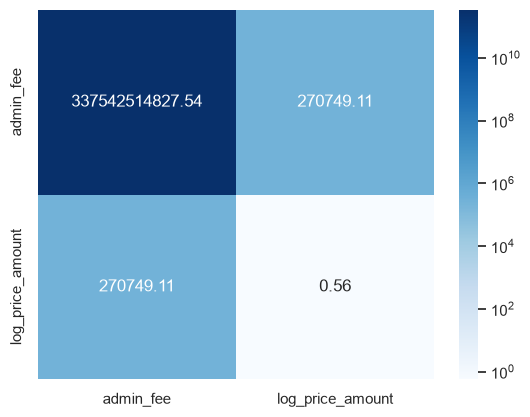

In [225]:
sns.heatmap(
    cov,
    annot=True,
    fmt=".2f",
    cmap="Blues",  # Usas el mapa creado
    norm=LogNorm(),
    xticklabels=["admin_fee", "log_price_amount"],
    yticklabels=["admin_fee", "log_price_amount"],
)

plt.show()

In [226]:
z = df[["admin_fee", "log_price_amount"]].mean().to_numpy()
z

array([6.43642203e+05, 2.03691718e+01])

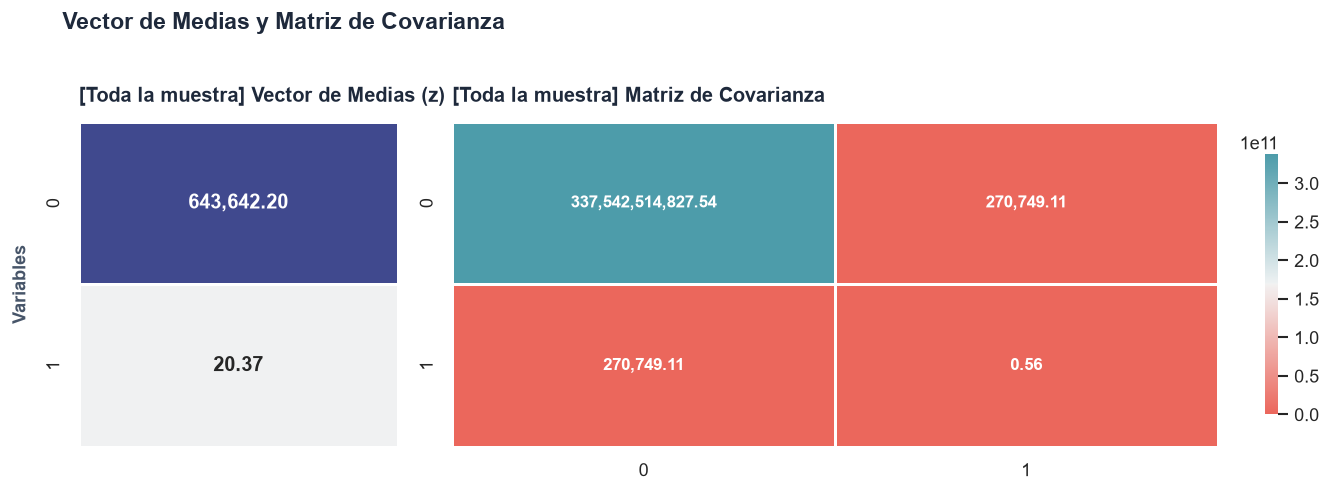

In [227]:
show_z_cov(z, cov, nombre="Toda la muestra")

El vector muestra que la tarifa de administración promedio ronda los 643,642.20 COP, mientras que el precio promedio (transformado con un ln) ronda los 20.3692 log COP.

La matriz de covarianzas da información sobre cómo se asocian las variables (diagonal secundaria) y qué tan dispersas están estas mismas (diagonal principal), siendo la cuota de administración la más variable de las 2, con una varianza de $S^2 = 337542514827.54$, es decir que su desviación estándar es $S = 580,984.09$ COP, constituyendo una variabilidad considerable respecto a la media y a la unidad de variable. Por otro lado, el precio es muy poco variable, esto gracias a la transformación logarítmica que se realizó anteriormente y, por último, la asociación entre estas 2 es positivas, indicando de esta manera que mientras más alto sea el precio del inmueble, mayor será su cuota de administración.

### Definir $\mu_0$

Según Jurgen D. Toloza Delgado, la media del precio de venta de los inmuebles de Bogotá es de 464.598.900 y, según El Tiempo, la cuota de administración media es de 190.000 pesos al mes.

Por esto, se define $\mu_0$ como:

$$
\begin{aligned}
\mu_0 = \begin{pmatrix} 190.000 \\ \ln(464.598.900) \end{pmatrix}
\end{aligned}
$$

- https://doi.org/10.17230/ingciencia.17.34.2
- https://www.eltiempo.com/economia/sectores/propiedad-horizontal-los-vacios-que-le-cuestan-millones-al-fisco-655558


In [228]:
mu_0 = np.array([190_000, np.log(464_598_900)])

mu_0

array([1.9000000e+05, 1.9956685e+01])

### Formular hipótesis

$$
\begin{aligned}
H_0 &: \text{El vector de medias real sigue lo que indica la literatura, } \boldsymbol{\mu} = \boldsymbol{\mu}_0 \\
H_1 &: \text{El vector de medias real difiere de lo indicado por la literatura, } \boldsymbol{\mu} \neq \boldsymbol{\mu}_0
\end{aligned}
$$

Se usa el caso donde no se conoce $\Sigma$



### Calcular la distancia de Mahalanobis

In [229]:
def mahalanobis_dist(df, colx, coly, x_mean_0, y_mean_0):

    Sigma = np.cov(df[colx], df[coly])
    Sigma_inv = np.linalg.inv(Sigma)

    mu = np.array([x_mean_0, y_mean_0])
    z = df[[colx, coly]].mean().to_numpy()

    diferencia = z - mu

    D2_punto = diferencia @ Sigma_inv @ diferencia
    D_punto = np.sqrt(D2_punto)

    return {
        "D2 (distancia cuadrada)": D2_punto,
        "D (distancia mahalanobis)": D_punto,
    }

In [230]:
distancia_vectores = mahalanobis_dist(
    df=df,
    colx="admin_fee",
    coly="log_price_amount",
    x_mean_0=mu_0[0],
    y_mean_0=mu_0[1],
)

distancia_vectores

{'D2 (distancia cuadrada)': np.float64(0.6165352286354028),
 'D (distancia mahalanobis)': np.float64(0.7851975729938311)}

La baja distancia de Mahalanobis indica que la media muestral y el vector de medias que se quiere probar como cierto es realmente baja, inclusive considerando la asociación de las variables, no obstante, para determinar la similitud estadística, falta realizar el cálculo del estadístico de prueba y su p-valor.

### Construir una región de confianza conjunta para $\mu$ 
Se supone $\alpha = 0.05$ 
    $$ \mathcal C_{0.95}
    =
    \left\{
    \boldsymbol{\mu}:
    n(\bar{\mathbf Z}-\boldsymbol{\mu})^\top
    S^{-1}
    (\bar{\mathbf Z}-\boldsymbol{\mu})
    \le
    \chi^2_{2,0.95}
    \right\}. $$

In [231]:
distancia_vectores["D2 (distancia cuadrada)"] * df.shape[0]

np.float64(12603.213143764904)

In [232]:
chi2.ppf(0.95, df=2)

np.float64(5.991464547107979)

Luego, la región de confianza conjunta es: 
$$\mathcal C_{0.95} =
\left\{
\boldsymbol{\mu}:
n(\bar{\mathbf Z}-\boldsymbol{\mu})^\top
S^{-1}
(\bar{\mathbf Z}-\boldsymbol{\mu})
\le
5.99
\right\}.
$$
La cual, al contrastarla con la distancia cuadrada por n, resulta en:

$$T^2_{obs} = n(\bar{\mathbf{Z}} - \boldsymbol{\mu}_0)^\top \boldsymbol{S}^{-1} (\bar{\mathbf{Z}} - \boldsymbol{\mu}_0) = 12603.21$$

Ya que $12603.21 > 5.991$
> Note que la distancia cuadrada por n no cumple con la condición de esa región de confianza. Es decir, el vector no pertenece a la región de confianza, por lo cual se rechaza $H_0: \boldsymbol{\mu} = \boldsymbol{\mu}_0$

### Realizar la prueba de hipótesis multivariada correspondiente y reportar estadístico, distribución, p-valor, decisión e interpretación en contexto.

In [233]:
def T2_test(df, colx, coly, x_mean_0, y_mean_0):
    n = len(df)
    p = 2  # Caso bivariado

    # Matriz de covarianza y su inversa
    Sigma = np.cov(df[colx], df[coly])
    Sigma_inv = np.linalg.inv(Sigma)

    # Vectores de medias
    mu_0 = np.array([x_mean_0, y_mean_0])
    z = df[[colx, coly]].mean().to_numpy()

    # Distancia de Mahalanobis cuadrada
    diferencia = z - mu_0
    D2 = diferencia @ Sigma_inv @ diferencia
    D = np.sqrt(D2)

    # Estadístico Hotelling T^2 y transformación a F
    T2 = n * D2
    F_stat = ((n - p) / (p * (n - 1))) * T2

    # p-valor usando la distribución F
    p_value = f.sf(F_stat, dfn=p, dfd=n - p)

    return {
        "n": n,
        "p": p,
        "Sigma": Sigma,
        "Sigma_inv": Sigma_inv,
        "mu_0": mu_0,
        "z": z,
        "diferencia": diferencia,
        "D2 (distancia cuadrada)": float(D2),
        "D (distancia Mahalanobis)": float(D),
        "Hotelling T2": float(T2),
        "Estadistico F": float(F_stat),
        "p-valor": float(p_value),
    }

In [234]:
T2_test(
    df=df,
    colx="admin_fee",
    coly="log_price_amount",
    x_mean_0=mu_0[0],
    y_mean_0=mu_0[1],
)

{'n': 20442,
 'p': 2,
 'Sigma': array([[3.37542515e+11, 2.70749107e+05],
        [2.70749107e+05, 5.61642463e-01]]),
 'Sigma_inv': array([[ 4.83037192e-12, -2.32856126e-06],
        [-2.32856126e-06,  2.90301391e+00]]),
 'mu_0': array([1.9000000e+05, 1.9956685e+01]),
 'z': array([6.43642203e+05, 2.03691718e+01]),
 'diferencia': array([4.53642203e+05, 4.12486799e-01]),
 'D2 (distancia cuadrada)': 0.6165352286354028,
 'D (distancia Mahalanobis)': 0.7851975729938311,
 'Hotelling T2': 12603.213143764904,
 'Estadistico F': 6301.298289187286,
 'p-valor': 0.0}

Si bien en un primer momento la baja distancia lucía como un buen indicio de no rechazo, al definir la región de confianza y calcular el estadístico F y el valor p, se determina que existe la suficiente evidencia estadística para rechazar la hipótesis nula.

Por lo tanto, la media poblacional no coincide con $\mu_0$, es decir, los log precios y las tarifas de administración reales difieren de $$ \begin{aligned} \mu_0 = \begin{pmatrix} 190.000 \\ \ln(464.598.900) \end{pmatrix}
\end{aligned} $$

Esto implica (por lo menos en la muestra tomada) que los valores medios de administración y de precios de vivienda son mayores a los que reporta la literatura, esto se puede deber muy posiblemente al claro sesgo que tiene la muestra hacia inmuebles de la parte norte de la ciudad, que es bien sabido que suelen ser zonas más costosas.

## 4. Interpretación gráfica.

In [235]:
def confidence_ellipse_from_cov(
    mean, cov, level=0.95, ax=None, label=None, **kwargs
):
    if ax is None:
        ax = plt.gca()

    c2 = chi2.ppf(level, df=2)

    eigvals, eigvecs = np.linalg.eigh(cov)
    order = eigvals.argsort()[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    width = 2 * np.sqrt(c2 * eigvals[0])
    height = 2 * np.sqrt(c2 * eigvals[1])

    angle = np.degrees(np.arctan2(*eigvecs[:, 0][::-1]))

    kwargs.setdefault("fill", False)
    ell = Ellipse(
        xy=mean, width=width, height=height, angle=angle, label=label, **kwargs
    )
    ax.add_patch(ell)
    return ell


def plot_multivariate_test_decision(
    df, colx, coly, x_mean_0, y_mean_0, alpha=0.05
):
    """
    Función para visualizar la decisión del test multivariado y mostrar el
    resumen analítico.
    """
    # 1. Llamar a la función T2_test para obtener todos los cálculos
    res = T2_test(df, colx, coly, x_mean_0, y_mean_0)

    n = res["n"]
    p = res["p"]
    Sigma = res["Sigma"]
    Sigma_inv = res["Sigma_inv"]
    mu0 = res["mu_0"]
    xbar = res["z"]
    d = res["diferencia"]

    # Usaremos el estadístico T equivalente del enfoque
    # asintótico/chi-cuadrado para la región visual o el chi2 de referencia
    T = res["Hotelling T2"]  # O n * D2
    crit = chi2.ppf(1 - alpha, df=p)
    rechaza = T > crit

    # 2. Figura: vista general + zoom sobre la región de confianza
    nivel = f"{1 - alpha:.0%}"
    # Semiancho y semialto de la región, y qué tan lejos queda mu0 de ella
    half = np.sqrt(crit * np.diag(Sigma) / n)
    ratio = np.max(np.abs(d) / half)
    mu0_en_zoom = ratio < 4
    pad = max(1.8, 1.25 * ratio) if mu0_en_zoom else 1.8

    # Tema y colores del proyecto
    sns.set_theme(style="white", font="sans-serif")
    color_media, color_region = sns.color_palette("mako", 2)
    color_mu0 = "#ec7063"

    fig, (ax, ax_zoom) = plt.subplots(1, 2, figsize=(15, 6.5), dpi=120)

    for a in (ax, ax_zoom):
        a.scatter(
            df[colx],
            df[coly],
            s=6,
            alpha=0.25,
            color="#94a3b8",
            rasterized=True,
            label="Observaciones muestrales",
        )
        a.plot(
            [mu0[0], xbar[0]],
            [mu0[1], xbar[1]],
            linestyle="--",
            linewidth=1.5,
            color="#475569",
            label=r"Vector $\bar{Z}-\mu_0$",
        )
        confidence_ellipse_from_cov(
            mean=xbar,
            cov=Sigma / n,
            level=1 - alpha,
            ax=a,
            fill=True,
            facecolor=(color_region, 0.25),
            edgecolor=color_region,
            linewidth=2,
            label=f"Región conjunta de confianza {nivel}",
        )
        a.scatter(
            [xbar[0]],
            [xbar[1]],
            s=70,
            color=color_media,
            edgecolor="white",
            zorder=3,
            label=r"Media muestral $\bar{Z}$",
        )
        a.scatter(
            [mu0[0]],
            [mu0[1]],
            marker="x",
            s=160,
            linewidths=3,
            color=color_mu0,
            zorder=3,
            label=r"Valor bajo $H_0$: $\mu_0$",
        )
        a.annotate(
            r"$\bar{Z}$",
            xy=xbar,
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=12,
            color="#1e293b",
        )
        a.annotate(
            r"$\mu_0$",
            xy=mu0,
            xytext=(8, -14),
            textcoords="offset points",
            fontsize=12,
            color="#1e293b",
        )
        a.set_xlabel(
            colx, fontsize=11, fontweight="bold", color="#475569", labelpad=10
        )
        a.set_ylabel(
            coly, fontsize=11, fontweight="bold", color="#475569", labelpad=10
        )
        a.xaxis.set_major_formatter("{x:,.10g}")
        a.yaxis.set_major_formatter("{x:,.10g}")
        a.grid(True, linestyle="--", alpha=0.3, color="#94a3b8")
        a.set_axisbelow(True)

    sns.despine(fig=fig, top=True, right=True)

    # 3. Zoom centrado en la media muestral
    ax_zoom.set_xlim(xbar[0] - pad * half[0], xbar[0] + pad * half[0])
    ax_zoom.set_ylim(xbar[1] - pad * half[1], xbar[1] + pad * half[1])
    ax.indicate_inset_zoom(ax_zoom, edgecolor="#475569")

    if not mu0_en_zoom:
        # mu0 no cabe en el zoom: flecha en su dirección, con la etiqueta
        # más allá de la punta y a un lado del vector, lejos de la región
        punta = xbar - 0.75 * pad * d / ratio
        ax_zoom.annotate(
            "",
            xy=punta,
            xytext=xbar,
            arrowprops={"arrowstyle": "->", "color": color_mu0},
        )
        ax_zoom.annotate(
            r"hacia $\mu_0$",
            xy=punta,
            xytext=(-6 * np.sign(d[0]), 6 * np.sign(d[1])),
            textcoords="offset points",
            ha="right" if d[0] > 0 else "left",
            va="bottom" if d[1] > 0 else "top",
            color=color_mu0,
        )

    # 4. Títulos y leyenda
    ax.set_title(
        "Vista general",
        fontsize=12,
        fontweight="bold",
        loc="left",
        color="#1e293b",
        pad=12,
    )
    ax_zoom.set_title(
        f"Zoom: región de confianza del {nivel}",
        fontsize=12,
        fontweight="bold",
        loc="left",
        color="#1e293b",
        pad=12,
    )

    if rechaza:
        donde = (
            f"fuera de la región {nivel} ({np.sqrt(T / crit):.3g} veces más"
            r" lejos de $\bar{Z}$ que su borde)"
        )
        decision = "se rechaza"
    else:
        donde = f"dentro de la región {nivel}"
        decision = "no se rechaza"
    fig.suptitle(
        "Relación entre región de confianza y prueba de hipótesis\n"
        rf"$\mu_0$ queda {donde}  $\Rightarrow$  {decision} $H_0$",
        fontsize=14,
        fontweight="bold",
        color="#1e293b",
        x=0.05,
        ha="left",
    )
    fig.legend(
        *ax.get_legend_handles_labels(),
        loc="lower center",
        ncol=5,
        frameon=False,
    )
    fig.tight_layout(rect=(0, 0.06, 1, 1))

    plt.show()

    # 6. Resumen numérico en consola
    print("=" * 70)
    print("PRUEBA DE HIPÓTESIS MULTIVARIADA (HOTELLING / T²)")
    print("=" * 70)

    print("\nHipótesis:")
    print("H0: μ = μ0")
    print("H1: μ ≠ μ0")

    print("\nValor bajo H0:")
    print("μ0 =", np.round(mu0, 4))

    print("\nMedia muestral:")
    print("Z̄ =", np.round(xbar, 4))

    print("\nDiferencia:")
    print("Z̄ - μ0 =", np.round(d, 4))

    print("\nMuestras (n):", n)
    print("\nMatriz de covarianzas Σ:")
    print(np.round(Sigma, 4))

    print("\nInversa Σ⁻¹:")
    print(np.round(Sigma_inv, 4))

    print("\n" + "-" * 75)
    print("RESULTADOS DE LA FUNCIÓN T2_test")
    print("-" * 75)
    for k, v in res.items():
        if isinstance(v, np.ndarray):
            print(f"{k}:\n{np.round(v, 4)}")
        else:
            print(f"{k}: {v}")

    print("\n" + "-" * 70)
    print("DECISIÓN")
    print("-" * 70)
    if rechaza:
        print(f"\nDECISIÓN: RECHAZAR H0 al nivel α = {alpha}.")
        print(
            "Geométricamente, μ0 está fuera de la región conjunta de "
            "confianza del 95%."
        )
    else:
        print(f"\nDECISIÓN: NO RECHAZAR H0 al nivel α = {alpha}.")
        print(
            "Geométricamente, μ0 está dentro de la región conjunta de "
            "confianza del 95%."
        )

    print("=" * 70)

    return res

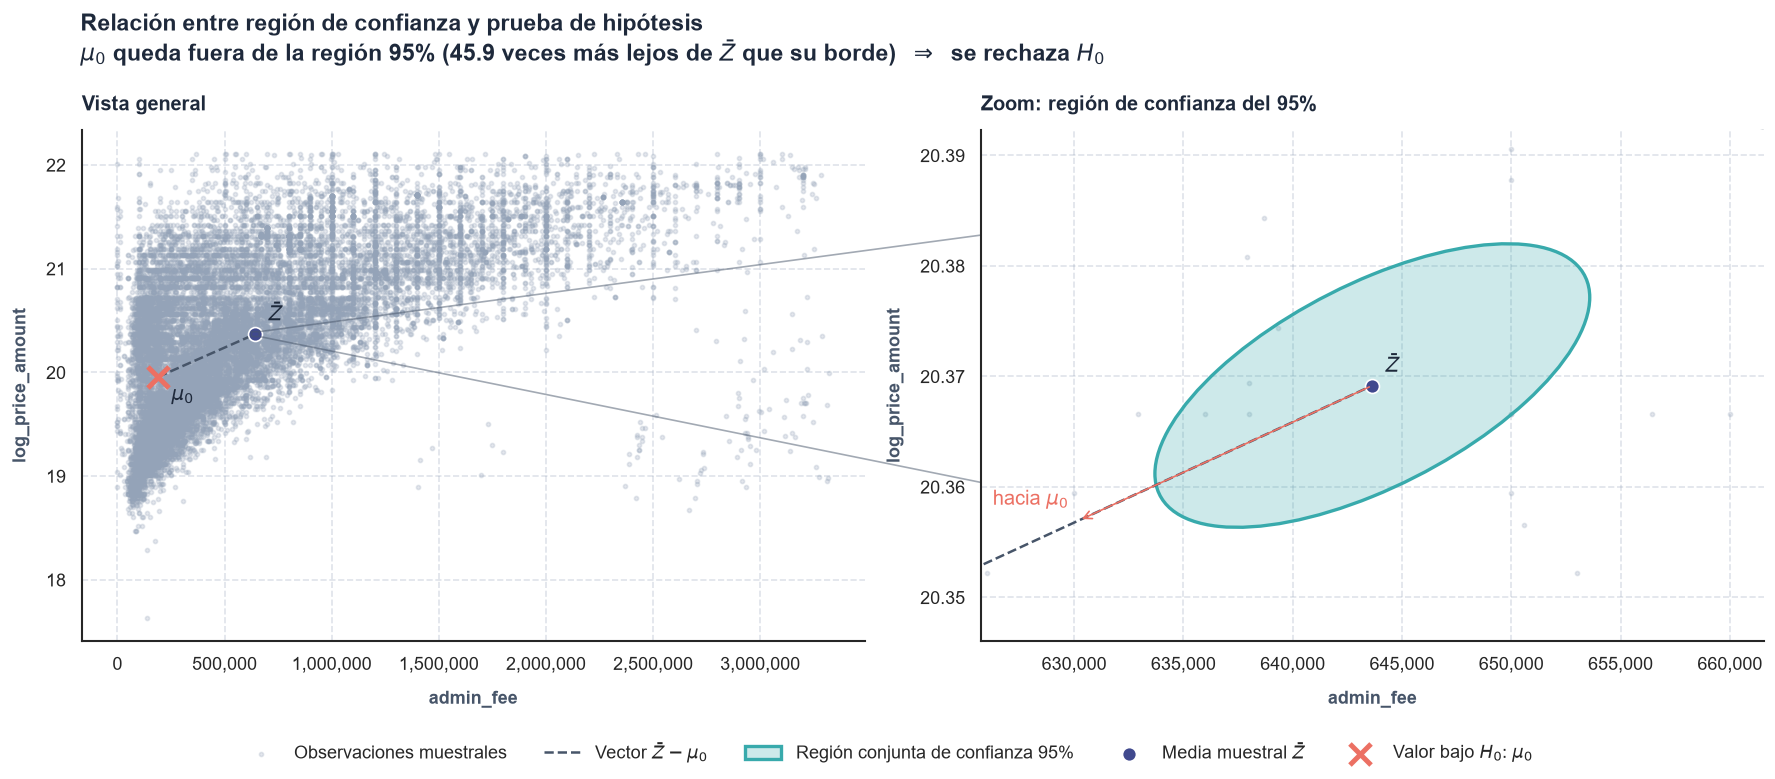

PRUEBA DE HIPÓTESIS MULTIVARIADA (HOTELLING / T²)

Hipótesis:
H0: μ = μ0
H1: μ ≠ μ0

Valor bajo H0:
μ0 = [1.90000e+05 1.99567e+01]

Media muestral:
Z̄ = [6.43642203e+05 2.03692000e+01]

Diferencia:
Z̄ - μ0 = [4.53642203e+05 4.12500000e-01]

Muestras (n): 20442

Matriz de covarianzas Σ:
[[3.37542515e+11 2.70749107e+05]
 [2.70749107e+05 5.61600000e-01]]

Inversa Σ⁻¹:
[[ 0.    -0.   ]
 [-0.     2.903]]

---------------------------------------------------------------------------
RESULTADOS DE LA FUNCIÓN T2_test
---------------------------------------------------------------------------
n: 20442
p: 2
Sigma:
[[3.37542515e+11 2.70749107e+05]
 [2.70749107e+05 5.61600000e-01]]
Sigma_inv:
[[ 0.    -0.   ]
 [-0.     2.903]]
mu_0:
[1.90000e+05 1.99567e+01]
z:
[6.43642203e+05 2.03692000e+01]
diferencia:
[4.53642203e+05 4.12500000e-01]
D2 (distancia cuadrada): 0.6165352286354028
D (distancia Mahalanobis): 0.7851975729938311
Hotelling T2: 12603.213143764904
Estadistico F: 6301.298289187286
p-valor: 0

{'n': 20442,
 'p': 2,
 'Sigma': array([[3.37542515e+11, 2.70749107e+05],
        [2.70749107e+05, 5.61642463e-01]]),
 'Sigma_inv': array([[ 4.83037192e-12, -2.32856126e-06],
        [-2.32856126e-06,  2.90301391e+00]]),
 'mu_0': array([1.9000000e+05, 1.9956685e+01]),
 'z': array([6.43642203e+05, 2.03691718e+01]),
 'diferencia': array([4.53642203e+05, 4.12486799e-01]),
 'D2 (distancia cuadrada)': 0.6165352286354028,
 'D (distancia Mahalanobis)': 0.7851975729938311,
 'Hotelling T2': 12603.213143764904,
 'Estadistico F': 6301.298289187286,
 'p-valor': 0.0}

In [236]:
plot_multivariate_test_decision(
    df=df,
    colx="admin_fee",
    coly="log_price_amount",
    x_mean_0=mu_0[0],
    y_mean_0=mu_0[1],
)

In [237]:
int(6.43642203e05), int(9.22592927e08)

(643642, 922592927)

Ya que $\mu_0$ está fuera de la región de confianza, se rechaza la hipótesis nula, esto respalda de manera gráfica y geométrica la decisión que se toma con el p value al 95% de confianza.

## 5. Comparación multivariada entre dos grupos

### Definir grupos

Se compararán tres parejas de grupos y las variables cuantitativas a comparar serán `log_price_amount` y `area_built_m2`.

Esta comparación se justifica bajo los hallazgos del cuaderno bivariate_eda, que se recuperan a continuación. Donde se logra ver que el precio de las viviendas difiere según el territorio, especialmente Chía. A esto se le suma que en el contexto inmobiliario muchas veces los precios y el metraje de los inmuebles cambia según la zona.

Además, se suma el análisis al cambio de `area_built_m2` que de nuevo muestra que Chía es donde se ve un mayor cambio respecto a los demás.

Ya que la variabilidad difiere entre grupos, se optó por investigar y se encontró que en lugar de usar $S_p$ se usa:

$$S_{diff} = \frac{S_1}{n_1} + \frac{S_2}{n_2}$$
Sin embargo, se mostrará el resultado usando los dos procedimientos con el fin de contrastar.

Esto es análogo a utilizar una diferencia de varianzas en el caso univariado donde

$$\text{Var}(\bar{X}_1 - \bar{X}_2) = \text{Var}(\bar{X}_1) + \text{Var}(\bar{X}_2) = \frac{\sigma_1^2}{n_1} + \frac{\sigma_2^2}{n_2}$$

De ahí se extrapola al caso multivariado de esta manera:

- La matriz de covarianza de un vector de media muestral $\mathbf{\bar{Z}}_1$ es $\frac{1}{n_1}\Sigma_1$.

- La matriz de covarianza del vector de media muestral $\mathbf{\bar{Z}}_2$ es $\frac{1}{n_2}\Sigma_2$.

Y, suponiendo independencia entre las observaciones de los grupos, se tiene

$$\text{Cov}(\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2) = \text{Cov}(\mathbf{\bar{Z}}_1) + \text{Cov}(\mathbf{\bar{Z}}_2) = \frac{\Sigma_1}{n_1} + \frac{\Sigma_2}{n_2}$$

O, en el caso muestral, también

$$\frac{S_1}{n_1} + \frac{S_2}{n_2}$$

Bajo eso, el valor de $T^2$ es:

$$T^2 = (\bar{\mathbf Z}_1-\bar{\mathbf Z}_2)^\top S_{diff}^{-1}(\bar{\mathbf Z}_1-\bar{\mathbf Z}_2)$$

Y, en este caso, el estadístico de prueba se define como 
$$F = \frac{\nu - p + 1}{\nu \, p} \, T^2 \;\sim\; F_{p,\; \nu - p + 1}$$

donde 
$$\nu = \frac{p + p^2}{\displaystyle\sum_{i=1}^{2} \frac{1}{n_i}\left\{ \operatorname{tr}\!\left[\left(\tfrac{1}{n_i} S_i \, S_{diff}^{-1}\right)^2\right] + \left(\operatorname{tr}\!\left[\tfrac{1}{n_i} S_i \, S_{diff}^{-1}\right]\right)^2 \right\}}$$

Note que el cálculo de los grados de libertad es similar al caso univariado (evidentemente guardando las distancias).

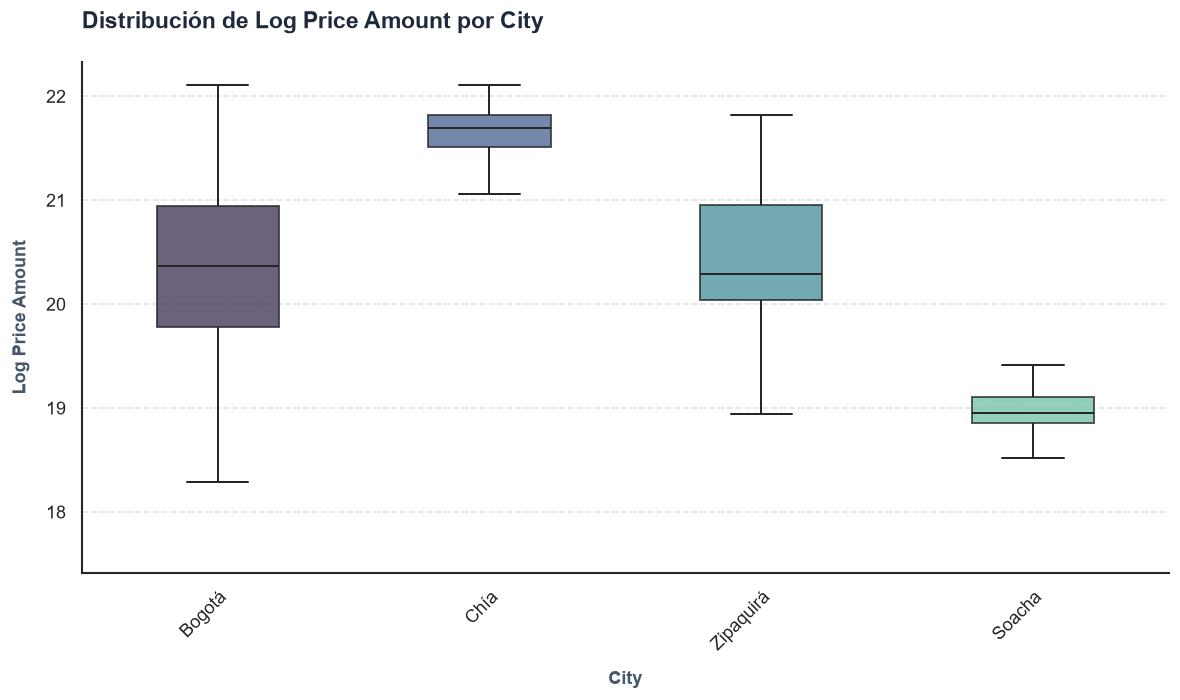

In [238]:
plot_segmented_boxplot(df, "log_price_amount", "city", show_points=False)

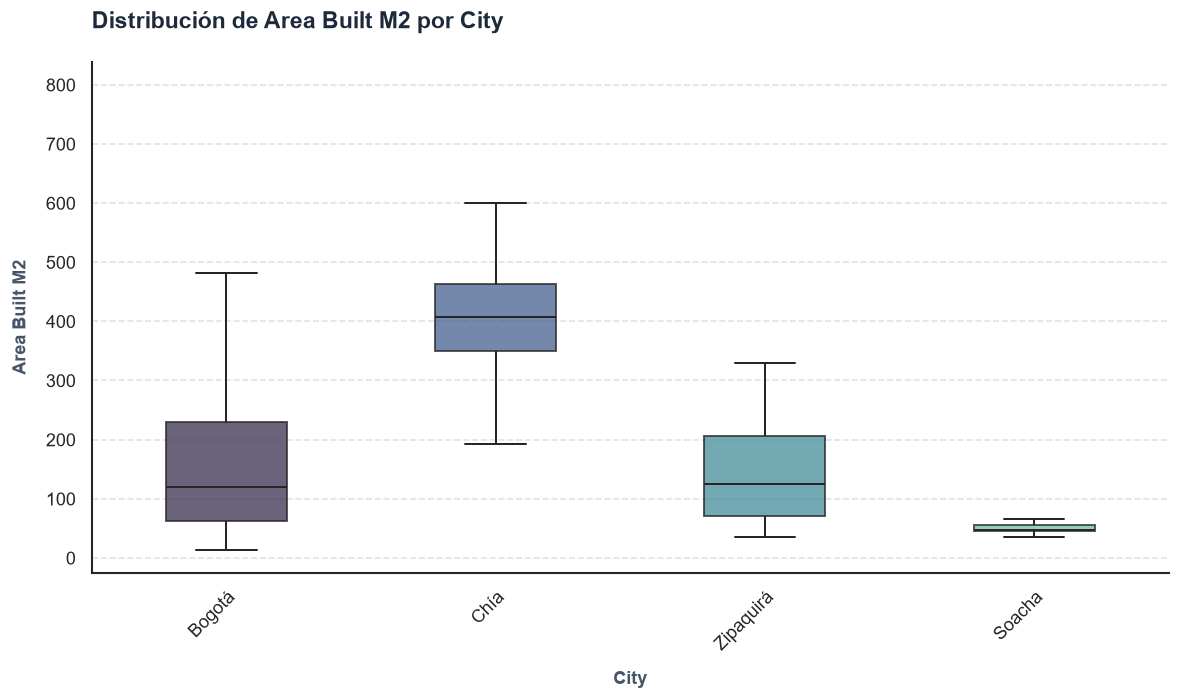

In [239]:
plot_segmented_boxplot(df, "area_built_m2", "city", show_points=False)

In [240]:
hub_pruebas_num_cat(df, "log_price_amount", ["city"])

,var_numerica,var_categorica,n_grupos,prueba,estadistico,p_valor,normalidad,homocedasticidad,decision,conclusion,post_hoc
0,log_price_amount,city,4,Kruskal-Wallis (H),823.5286,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,Bogotá vs Chía (p=0.0000); Bogotá vs Soacha (p...


In [241]:
hub_pruebas_num_cat(df, "area_built_m2", ["city"])

,var_numerica,var_categorica,n_grupos,prueba,estadistico,p_valor,normalidad,homocedasticidad,decision,conclusion,post_hoc
0,area_built_m2,city,4,Kruskal-Wallis (H),561.4555,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,Bogotá vs Chía (p=0.0000); Bogotá vs Soacha (p...


#### Viviendas de Bogotá vs. viviendas de Chía

In [242]:
def hotteling_comparison(df1, df2, colx, coly, alpha=0.05):
    p = 2  # Caso bivariado
    z_1 = df1[[colx, coly]].mean().to_numpy()
    z_2 = df2[[colx, coly]].mean().to_numpy()

    cov1 = df1[[colx, coly]].cov().to_numpy()
    cov2 = df2[[colx, coly]].cov().to_numpy()

    cov_ig = np.allclose(cov1, cov2, rtol=1e-4, atol=1e-6)

    S_diff = cov1 / len(df1) + cov2 / len(df2)
    S_pooled = ((len(df1) - 1) * cov1 + (len(df2) - 1) * cov2) / (
        len(df1) + len(df2) - 2
    )

    Z = z_1 - z_2
    # Usar la matriz para vars diferentes
    T2_diff = Z.T @ np.linalg.inv(S_diff) @ Z
    # S_diff^{-1}
    S_diff_inv = np.linalg.inv(S_diff)

    # (1/n_i) * S_i * S_diff^{-1}  para cada grupo
    A1 = (cov1 / len(df1)) @ S_diff_inv
    A2 = (cov2 / len(df2)) @ S_diff_inv

    # Denominador de nu: suma sobre i de (1/n_i) * { tr[A_i^2] + (tr[A_i])^2 }
    denominador = (np.trace(A1 @ A1) + np.trace(A1) ** 2) / len(df1) + (
        np.trace(A2 @ A2) + np.trace(A2) ** 2
    ) / len(df2)

    # Grados de libertad ajustados
    nu = (p + p**2) / denominador

    # Transformación a F y p-valor
    F_stat_diff = (nu - p + 1) / (nu * p) * T2_diff
    p_value_diff = f.sf(F_stat_diff, dfn=p, dfd=nu - p + 1)

    reject_null_diff = p_value_diff < alpha

    # usar la matriz de covarianza común suponemos que son iguales
    # (caso de comparasion teorica)
    S_pooled_scaled = S_pooled * (1 / len(df1) + 1 / len(df2))
    T2_pooled = Z.T @ np.linalg.inv(S_pooled_scaled) @ Z

    F_stat_pooled = (
        (len(df1) + len(df2) - p - 1)
        / (p * (len(df1) + len(df2) - 2))
        * T2_pooled
    )

    p_value_pooled = f.sf(
        F_stat_pooled, dfn=p, dfd=len(df1) + len(df2) - p - 1
    )

    reject_null_pooled = p_value_pooled < alpha

    return {
        "z_1": z_1,
        "z_2": z_2,
        "cov1": cov1,
        "cov2": cov2,
        "matriz de covarianzas comun": cov_ig,
        "S_diff": S_diff,
        "S_pooled": S_pooled,
        "Z": Z,
        "nu": nu,
        "T2_diff": T2_diff,
        "F_stat_diff": F_stat_diff,
        "p_value_diff": p_value_diff,
        "reject_null_diff": reject_null_diff,
        "T2_pooled": T2_pooled,
        "F_stat_pooled": F_stat_pooled,
        "p_value_pooled": p_value_pooled,
        "reject_null_pooled": reject_null_pooled,
    }

In [243]:
df_bogota = df[df["city"] == "Bogotá"].copy()
df_chia = df[df["city"] == "Chía"].copy()

In [244]:
def plot_group_comparison(
    df1,
    df2,
    label1="Bogotá",
    label2="Chía",
    x="area_built_m2",
    y="log_price_amount",
):
    # Unir ambos DataFrames para facilitar el gráfico conjunto con Seaborn
    df1 = df1.copy()
    df2 = df2.copy()
    df1["grupo"] = label1
    df2["grupo"] = label2
    df_combined = pd.concat([df1, df2], ignore_index=True)

    # Calcular métricas para el recuadro (Covarianza cruzada y Correlación
    # de Pearson)
    # cov(x, y) de la matriz de covarianza devuelta por .cov() en la
    # posición [0, 1]
    cov1 = df1[[x, y]].cov().iloc[0, 1]
    corr1 = df1[[x, y]].corr().iloc[0, 1]

    cov2 = df2[[x, y]].cov().iloc[0, 1]
    corr2 = df2[[x, y]].corr().iloc[0, 1]

    # Configurar la figura (tema y paleta del proyecto)
    sns.set_theme(style="white", font="sans-serif")
    color1, color2 = sns.color_palette("mako", 2)
    plt.figure(figsize=(10, 6), dpi=120)

    # Crear scatter plot con líneas de tendencia (regplot o lmplot integrado
    # en scatterplot con hue)
    sns.scatterplot(
        data=df_combined,
        x=x,
        y=y,
        hue="grupo",
        alpha=0.5,
        s=18,
        linewidth=0,
        palette={label1: color1, label2: color2},
    )

    # Añadir líneas de tendencia (regresión lineal) por separado para cada
    # grupo
    sns.regplot(
        data=df1,
        x=x,
        y=y,
        scatter=False,
        color=color1,
        line_kws={"linestyle": "--", "linewidth": 2},
    )
    sns.regplot(
        data=df2,
        x=x,
        y=y,
        scatter=False,
        color=color2,
        line_kws={"linestyle": "--", "linewidth": 2},
    )

    # Texto descriptivo con las métricas (recuadro)
    texto_stats = (
        f"--- {label1} ---\n"
        f"Cov: {cov1:,.2f}\n"
        f"Corr: {corr1:.3f}\n\n"
        f"--- {label2} ---\n"
        f"Cov: {cov2:,.2f}\n"
        f"Corr: {corr2:.3f}"
    )

    # Añadir caja de texto en la esquina superior izquierda del gráfico
    plt.gca().text(
        0.05,
        0.95,
        texto_stats,
        transform=plt.gca().transAxes,
        fontsize=10,
        color="#1e293b",
        verticalalignment="top",
        bbox=dict(
            boxstyle="round", facecolor="white", alpha=0.9, edgecolor="#94a3b8"
        ),
    )

    # Personalización de títulos y ejes
    plt.title(
        f"Comparación de Tendencias y Variación Mutua: {label1} vs {label2}",
        fontsize=14,
        fontweight="bold",
        pad=20,
        loc="left",
        color="#1e293b",
    )
    plt.xlabel(
        "Área Construida (m²)",
        fontsize=11,
        fontweight="bold",
        color="#475569",
        labelpad=10,
    )
    plt.ylabel(
        "Precio (COP)",
        fontsize=11,
        fontweight="bold",
        color="#475569",
        labelpad=10,
    )
    plt.legend(title="Grupos", frameon=False)
    plt.grid(True, linestyle="--", alpha=0.3, color="#94a3b8")
    plt.gca().set_axisbelow(True)
    sns.despine(top=True, right=True)
    plt.tight_layout()
    plt.show()

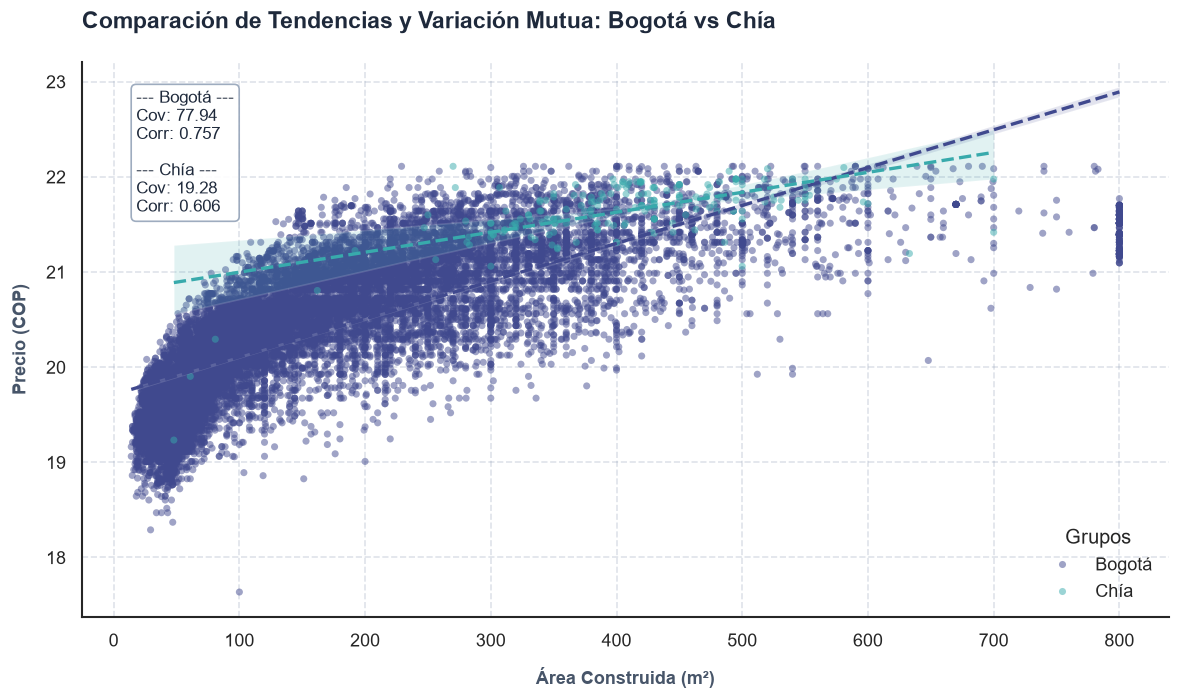

In [245]:
plot_group_comparison(df_bogota, df_chia, label1="Bogotá", label2="Chía")

Note cómo la covarianza y la correlación cambia de grupo a grupo, esto sugiere que el mejor método es aquel que no asume que comparten la misma matriz de covarianzas.

In [246]:
resultados_1 = hotteling_comparison(
    df_bogota, df_chia, "area_built_m2", "log_price_amount"
)
resultados_1

{'z_1': array([165.37171486,  20.36740647]),
 'z_2': array([406.26034973,  21.63971404]),
 'cov1': array([[1.95976037e+04, 7.79376490e+01],
        [7.79376490e+01, 5.40814868e-01]]),
 'cov2': array([[9.19229375e+03, 1.92834392e+01],
        [1.92834392e+01, 1.10173938e-01]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[5.01318988e+01, 1.06998455e-01],
        [1.06998455e-01, 6.16078349e-04]]),
 'S_pooled': array([[1.95021704e+04, 7.73996962e+01],
        [7.73996962e+01, 5.36865203e-01]]),
 'Z': array([-240.88863487,   -1.27230758]),
 'nu': np.float64(198.24076684075223),
 'T2_diff': np.float64(2640.1092177604187),
 'F_stat_diff': np.float64(1313.3957635280794),
 'p_value_diff': np.float64(1.0171005330759338e-114),
 'reject_null_diff': np.True_,
 'T2_pooled': np.float64(631.9652323228495),
 'F_stat_pooled': np.float64(315.9670351645726),
 'p_value_pooled': np.float64(7.445990906358387e-136),
 'reject_null_pooled': np.True_}

In [247]:
int(7.44149388e10)

74414938800

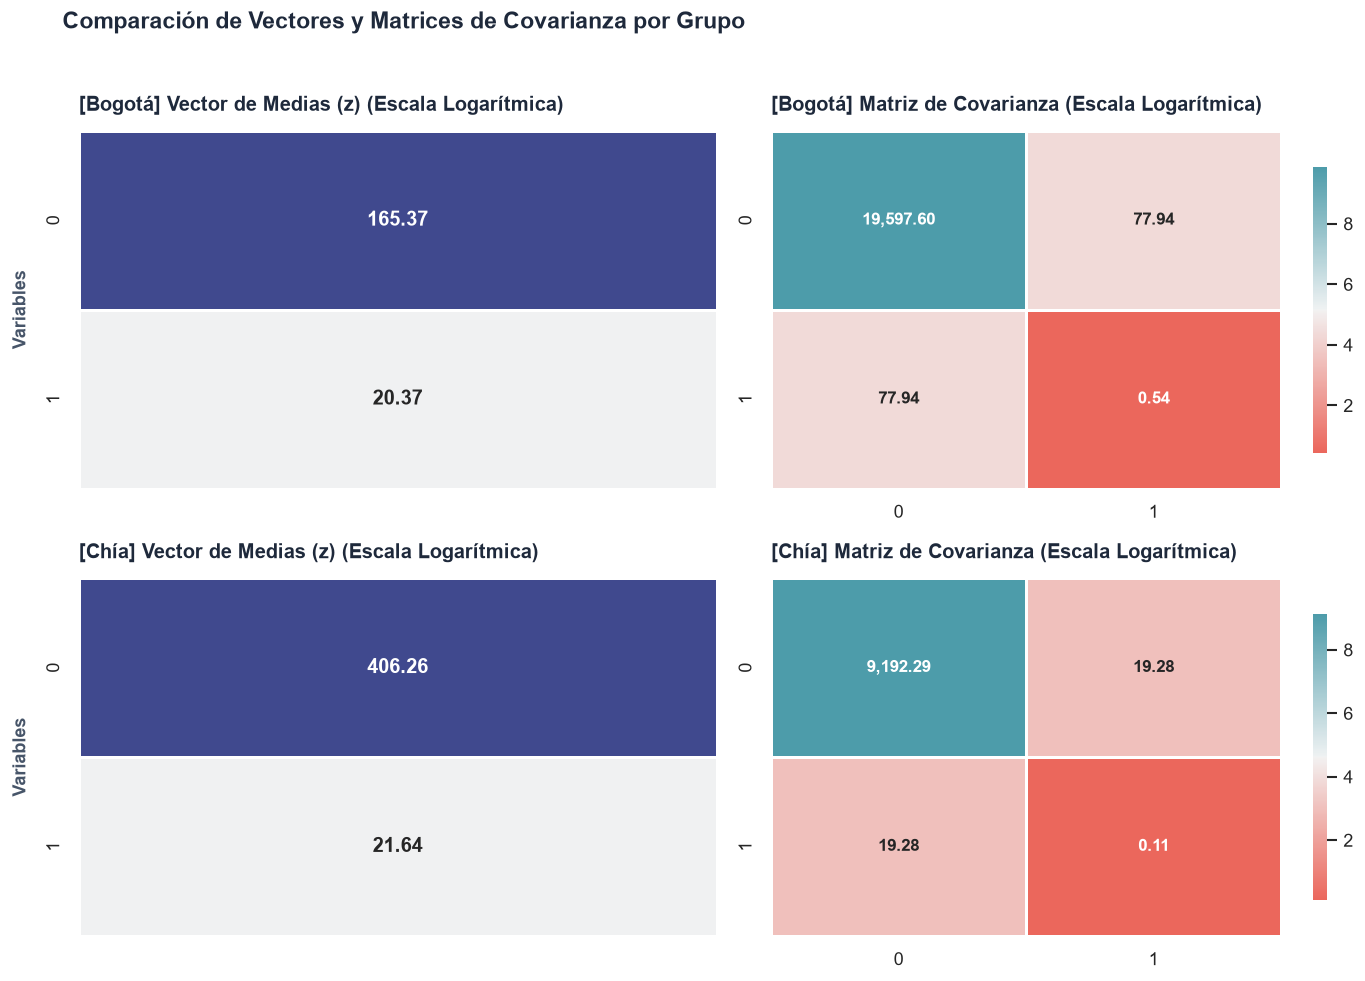

In [248]:
resultados_dict = {
    "Bogotá": [resultados_1["z_1"], resultados_1["cov1"]],
    "Chía": [resultados_1["z_2"], resultados_1["cov2"]],
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [249]:
# diferencia entre precios en escala original

precios_log_bog = resultados_1["z_1"][1]
precios_log_chia = resultados_1["z_2"][1]

print(
    f"Precios en escala log\n Bogota {precios_log_bog}\n"
    f"  Chia {precios_log_chia}"
)
print(
    f"Precios en escala original\n Bogota {np.exp(precios_log_bog):,.2f}\n"
    f"  Chia {np.exp(precios_log_chia):,.2f}"
)

Precios en escala log
 Bogota 20.367406467557707
  Chia 21.63971404424168
Precios en escala original
 Bogota 700,571,135.05
  Chia 2,500,393,719.55


Vea cómo la primera componente de los vectores de medias difiere en buena medida entre Chía y Bogotá, esto da un primer indicio de rechazo de la prueba, asimismo, en la segunda componente los precios parecen no cambiar mucho, no obstante, recuerde que están en escala logarítmica y en la escala original la diferencia es realmente amplia (aparece en la celda que está justo arriba).

Note además que las matrices de covarianzas no son iguales o siquiera similares de grupo a grupo, por lo que las conclusiones que a continuación se exponen corresponden a aquellas extraídas con la matriz $S_{diff}$ que se planteó al principio de la sección (esos valores son aquellos con sufijo `_diff` en el diccionario). Dicho eso, el p valor de la prueba fue $1.0171005330759338 \times 10^{-114}$, por lo tanto, a un nivel de confianza del 95%, se rechaza la hipótesis nula y por lo tanto se concluye que los 2 vectores de medias son estadísticamente diferentes.

En el contexto, esto implica que el comportamiento entre Chía y Bogotá difiere de manera significativa, lo cual desemboca en el potencial planteamiento de estrategias de compra venta diferentes según la zona, pues esa diferencia podría generar que públicos diferentes sean los interesados en cada una de las ciudades (municipio en el caso de Chía).

#### Viviendas de Bogotá vs. viviendas de Zipa

In [250]:
df_zipa = df[df["city"] == "Zipaquirá"].copy()

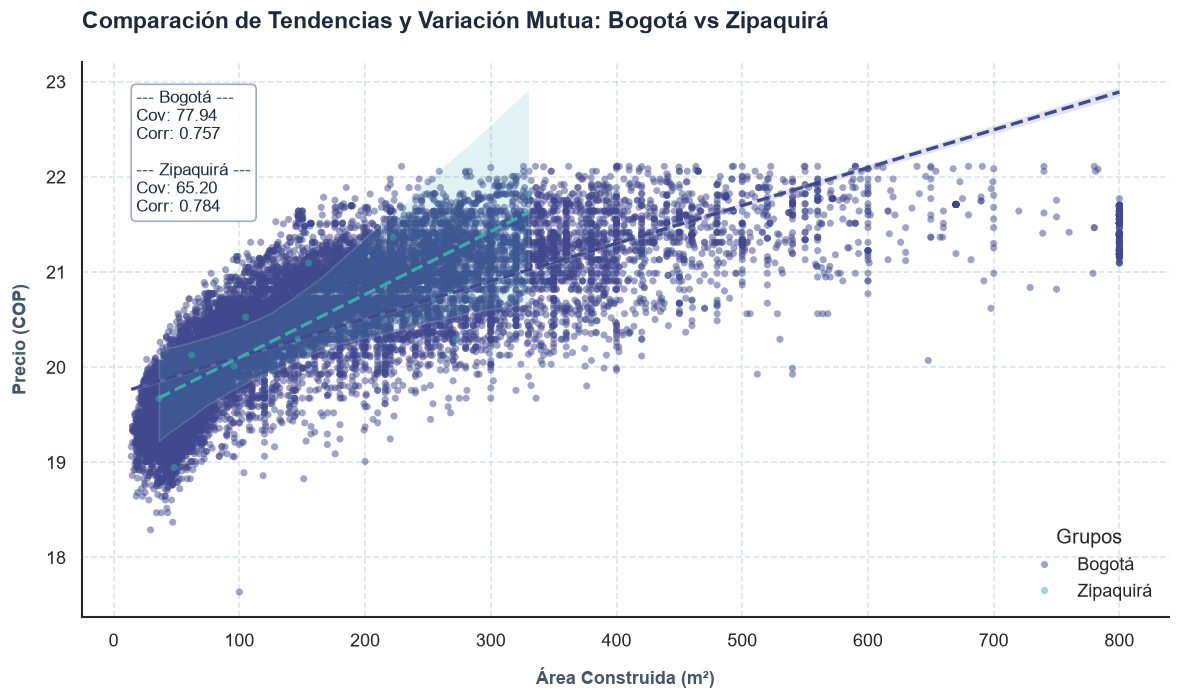

In [251]:
plot_group_comparison(df_bogota, df_zipa, label1="Bogotá", label2="Zipaquirá")

In [252]:
resultados_2 = hotteling_comparison(
    df_bogota, df_zipa, "area_built_m2", "log_price_amount"
)
resultados_2

{'z_1': array([165.37171486,  20.36740647]),
 'z_2': array([147.27674   ,  20.41351639]),
 'cov1': array([[1.95976037e+04, 7.79376490e+01],
        [7.79376490e+01, 5.40814868e-01]]),
 'cov2': array([[9.83831045e+03, 6.51965210e+01],
        [6.51965210e+01, 7.03434292e-01]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[9.84806293e+02, 6.52353056e+00],
        [6.52353056e+00, 7.03703421e-02]]),
 'S_pooled': array([[1.95932346e+04, 7.79319448e+01],
        [7.79319448e+01, 5.40887672e-01]]),
 'Z': array([18.09497486, -0.04610992]),
 'nu': np.float64(10.016669925471723),
 'T2_diff': np.float64(1.3468448644727555),
 'F_stat_diff': np.float64(0.6061922612067915),
 'p_value_diff': np.float64(0.5662280754081911),
 'reject_null_diff': np.False_,
 'T2_pooled': np.float64(0.7705685788779268),
 'F_stat_pooled': np.float64(0.3852651239268787),
 'p_value_pooled': np.float64(0.6802752792444451),
 'reject_null_pooled': np.False_}

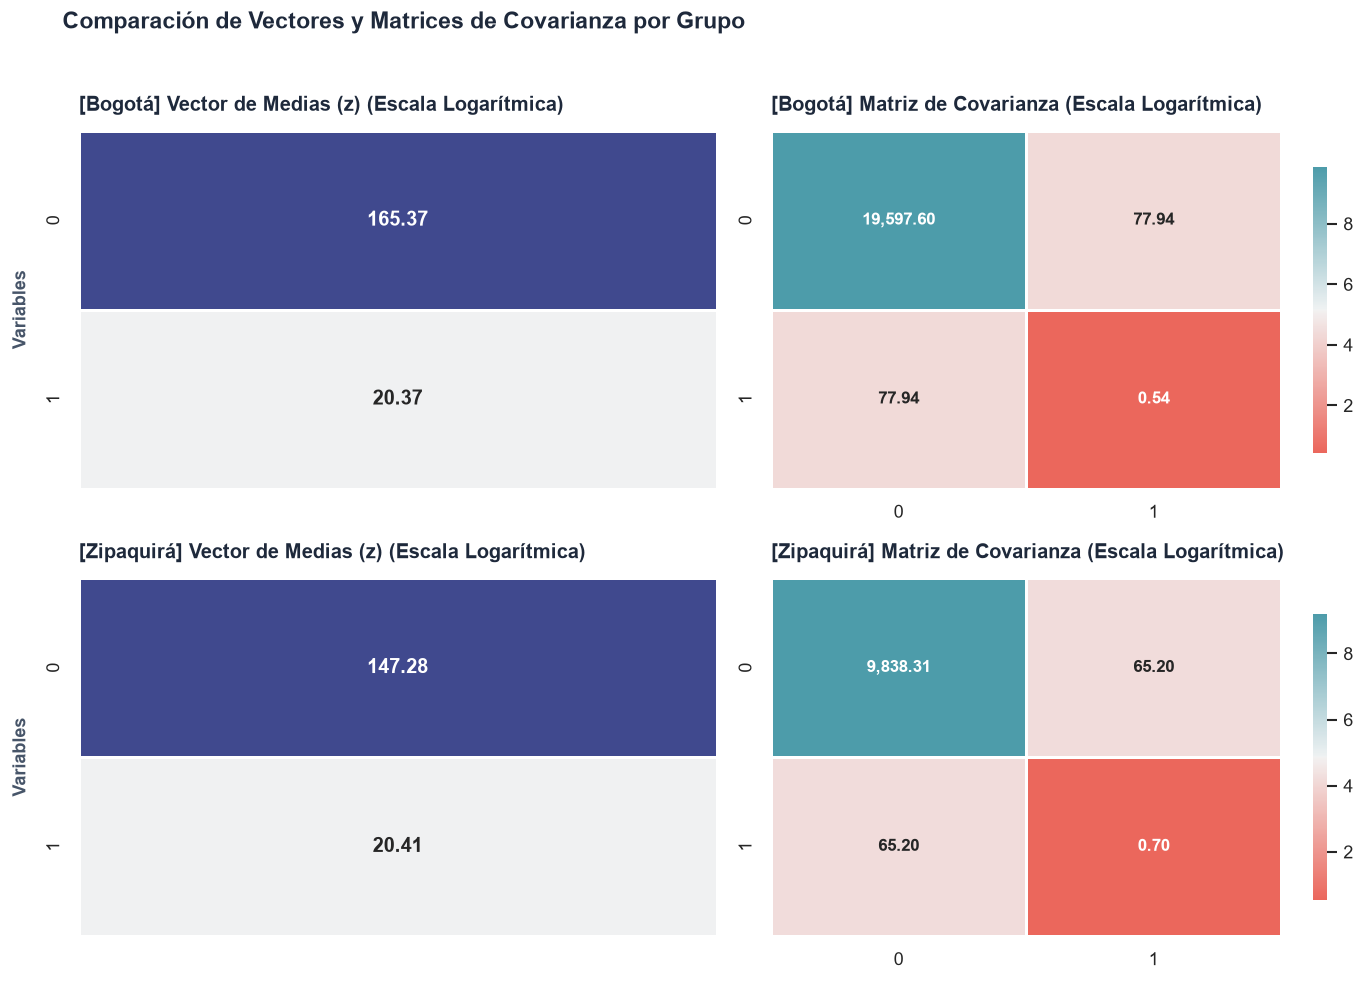

In [253]:
resultados_dict = {
    "Bogotá": [resultados_2["z_1"], resultados_2["cov1"]],
    "Zipaquirá": [resultados_2["z_2"], resultados_2["cov2"]],
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [254]:
# diferencia entre precios en escala original

precios_log_bog = resultados_2["z_1"][1]
precios_log_zipa = resultados_2["z_2"][1]

print(
    f"Precios en escala log\n Bogota {precios_log_bog}\n"
    f"  Zipa {precios_log_zipa}"
)
print(
    f"Precios en escala original\n Bogota {np.exp(precios_log_bog):,.2f}\n"
    f"  Zipa {np.exp(precios_log_zipa):,.2f}"
)

Precios en escala log
 Bogota 20.367406467557707
  Zipa 20.41351639050789
Precios en escala original
 Bogota 700,571,135.05
  Zipa 733,630,747.00


In [255]:
df_zipa.shape[0], df_bogota.shape[0], df_chia.shape[0]

(10, 20095, 187)

En este caso, la primera componente (que de nuevo corresponde al área construida) no tiene una diferencia tan grande como en la comparación anterior, asimismo, los precios (incluso en su escala real) no son especialmente diferentes entre sí, esto da un buen primer indicio sobre el no rechazo de la prueba.

Puesto que las matrices de cov no se parecen en gran medida, se utilizarán los cálculos que corresponden al uso de la matriz $S_{diff}$, usando dicha matriz el p valor fue aproximadamente de **0.566**, por lo que a un 95% de confianza no hay evidencia estadística suficiente para rechazar la hipótesis nula, por lo tanto, no es posible afirmar que los vectores difieren entre sí (recuerde que eso no hace que el hecho de que los 2 vectores de medias sean iguales cierto).

Bajo el contexto inmobiliario implica que las viviendas de Bogotá y Zipa se tienen características de precio y área construida similares, por lo que se les puede ofrecer a perfiles de clientes similares.

> Nota: Estas conclusiones se deben tomar con cautela, pues la cantidad de datos sobre Zipa es minúscula frente a los datos que se tienen sobre Bogotá, específicamente 10 vs 20095, por lo que estas conclusiones no son del todo confiables y se tienen que estimar sobre un conjunto con mayor representatividad del municipio, esto se escogió principalmente por la similitud inicial que se vio entre las zonas y para ejemplificar una prueba que no se rechaza.

#### Viviendas de Bogotá vs. viviendas de Soacha

In [256]:
df_soa = df[df["city"] == "Soacha"].copy()

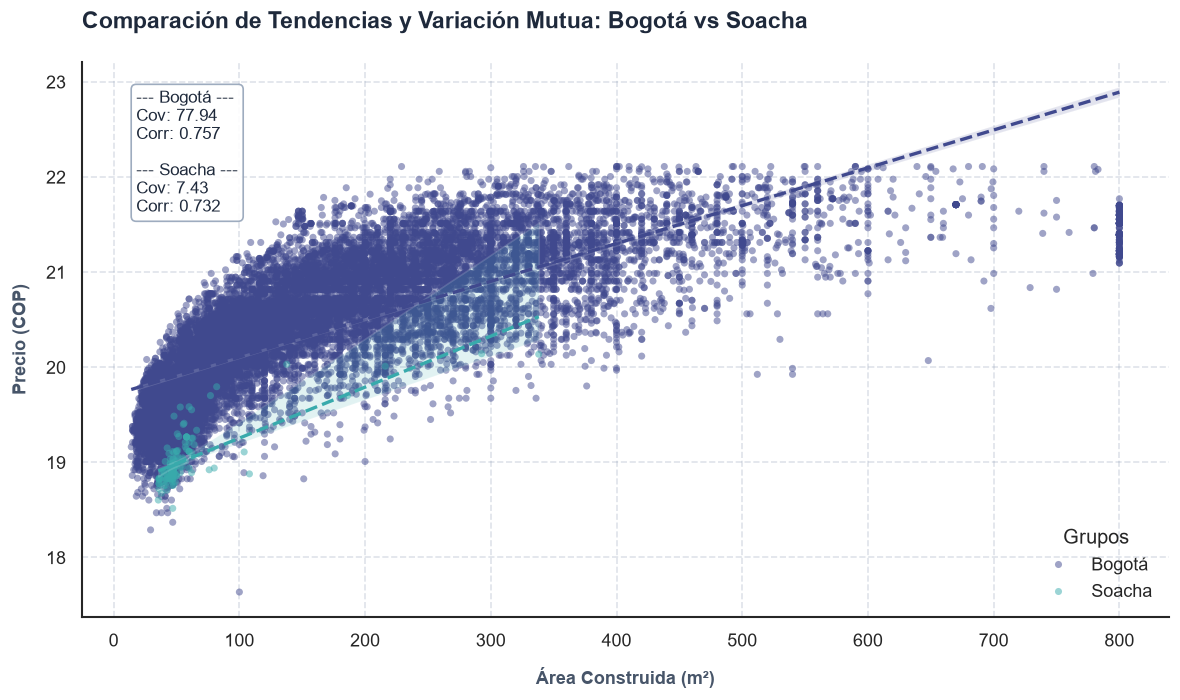

In [257]:
plot_group_comparison(df_bogota, df_soa, label1="Bogotá", label2="Soacha")

In [258]:
resultados_3 = hotteling_comparison(
    df_bogota, df_soa, "area_built_m2", "log_price_amount"
)
resultados_3

{'z_1': array([165.37171486,  20.36740647]),
 'z_2': array([56.09481333, 19.01876982]),
 'cov1': array([[1.95976037e+04, 7.79376490e+01],
        [7.79376490e+01, 5.40814868e-01]]),
 'cov2': array([[1.38575438e+03, 7.42782896e+00],
        [7.42782896e+00, 7.44049855e-02]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[1.02136103e+01, 5.33973195e-02],
        [5.33973195e-02, 5.22946144e-04]]),
 'S_pooled': array([[1.94635542e+04, 7.74186566e+01],
        [7.74186566e+01, 5.37381826e-01]]),
 'Z': array([109.27690153,   1.34863665]),
 'nu': np.float64(175.01742268410422),
 'T2_diff': np.float64(3647.791419180609),
 'F_stat_diff': np.float64(1813.4744859108637),
 'p_value_diff': np.float64(2.945235229959587e-117),
 'reject_null_diff': np.True_,
 'T2_pooled': np.float64(633.4244820266085),
 'F_stat_pooled': np.float64(316.6965954943094),
 'p_value_pooled': np.float64(3.701965990577185e-136),
 'reject_null_pooled': np.True_}

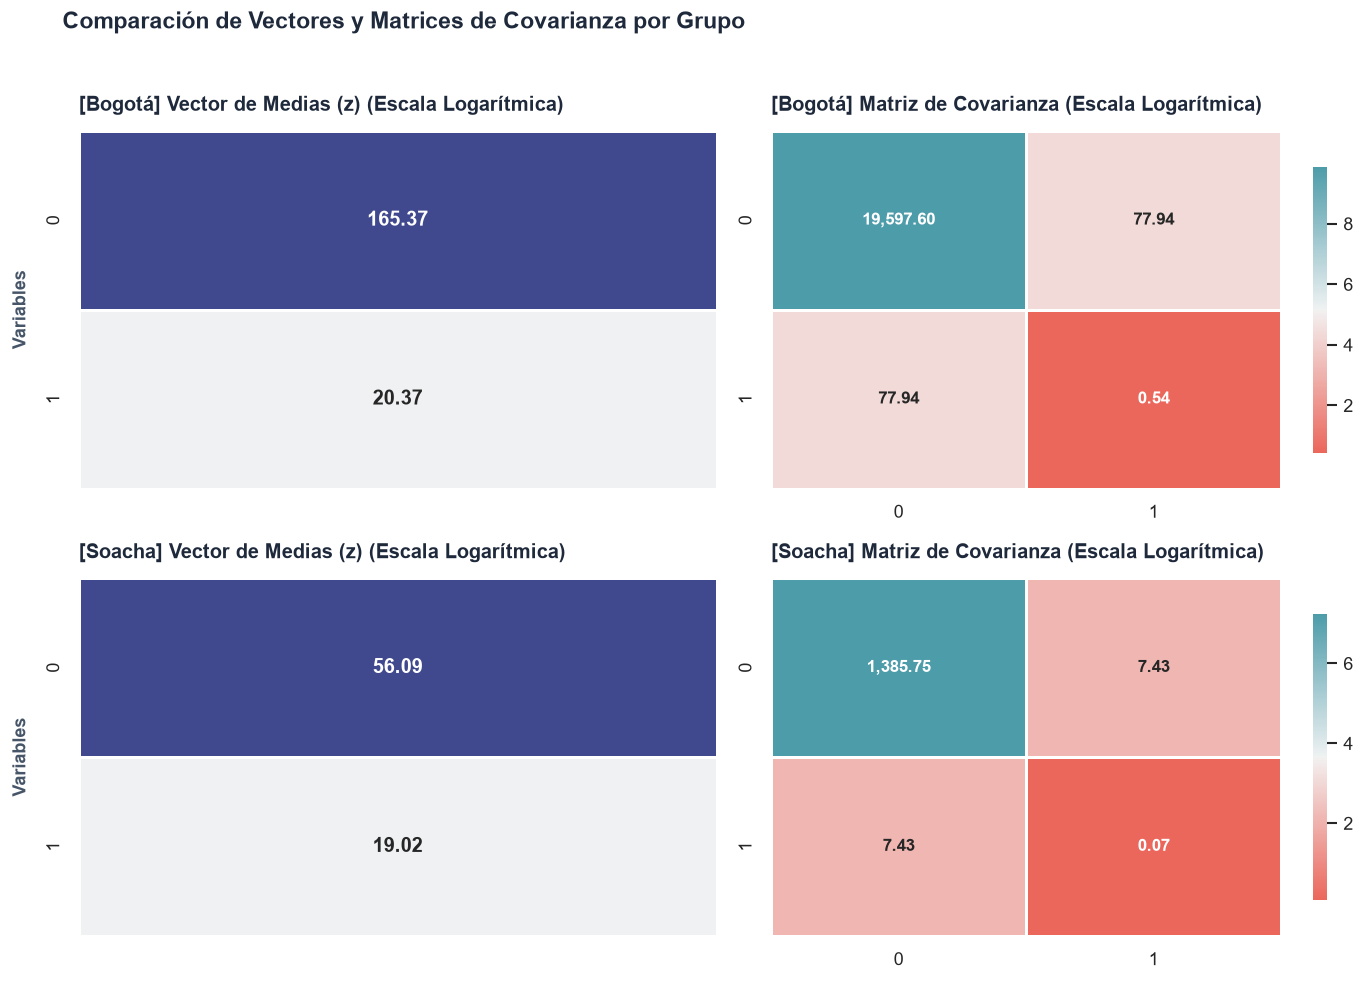

In [259]:
resultados_dict = {
    "Bogotá": [resultados_3["z_1"], resultados_3["cov1"]],
    "Soacha": [resultados_3["z_2"], resultados_3["cov2"]],
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [260]:
# diferencia entre precios en escala original

precios_log_bog = resultados_3["z_1"][1]
precios_log_soa = resultados_3["z_2"][1]

print(
    f"Precios en escala log\n Bogota {precios_log_bog}\n"
    f"  Soacha {precios_log_soa}"
)
print(
    f"Precios en escala original\n Bogota {np.exp(precios_log_bog):,.2f}\n"
    f"  Soacha {np.exp(precios_log_soa):,.2f}"
)

Precios en escala log
 Bogota 20.367406467557707
  Soacha 19.018769817243864
Precios en escala original
 Bogota 700,571,135.05
  Soacha 181,864,018.97


Para este caso, la diferencia entre las áreas construidas es amplia, siendo menor en Soacha, y lo mismo ocurre con el precio, hay una diferencia realmente alta donde Soacha es la que menores precios tiene en promedio, esto es un primer indicio de que la prueba será rechazada.

Puesto que las matrices de cov son diferentes entre sí, se opta por basarse en las conclusiones extraídas de $S_{diff}$. Donde el p valor es de $2.945235229959587 \times 10^{-117}$, por lo que a un 95% de confianza se rechaza la hipótesis nula y por lo tanto hay suficiente evidencia para afirmar que los vectores de medias de las dos zonas son estadísticamente diferentes.

En el contexto inmobiliario indica que se pueden ofrecer las viviendas de Soacha a clientes que busquen opciones más asequibles que las que hay en los otros municipios o en Bogotá.

### ¿Por qué el procedimiento es análogo a la comparación entre medias?

#### Cuando se asumen las varianzas iguales.

Se toma la variabilidad ponderada como $$S_p^2 = \frac{(n_1 - 1)S_1^2 + (n_2 - 1)S_2^2}{n_1 + n_2 - 2}$$

y el estadístico t se calcula de la siguiente forma:

$$t = \frac{(\bar{x}_1 - \bar{x}_2) - (\mu_1 - \mu_2)}{S_p \sqrt{\frac{1}{n_1} + \frac{1}{n_2}}}$$

pero en forma cuadrada, que es con aquella que la analogía es más clara, es:

$$t^2 = \frac{(\bar{x}_1 - \bar{x}_2)^2}{S_p^2 \left(\frac{1}{n_1} + \frac{1}{n_2}\right)}$$

Vea que los cálculos son iguales solo que generalizados a matrices, si bien la fórmula de $S_p^2$, no es muy diferente la comparación interesante reside en el cálculo de los estadísticos en sí mismos, pues se tiene que 

$$T^2 = (\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)^\top \left[ S_p \left( \frac{1}{n_1} + \frac{1}{n_2} \right) \right]^{-1} (\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)$$

donde el término $[S_p ( \frac{1}{n_1} + \frac{1}{n_2})]^{-1}$ es análogo al denominador del cálculo del estadístico t, pues en el mundo matricial la inversa de una matriz tiene el mismo efecto que utilizar un número para dividir, además, los términos $(\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)^\top ... \space (\mathbf{\bar{Z}}_1 - \mathbf{\bar{Z}}_2)$ son análogos a la diferencia $\bar{x}_1 - \bar{x}_2$, solo que en este caso 'elevada al cuadrado'.

El término $[S_p ( \frac{1}{n_1} + \frac{1}{n_2})]^{-1}$ está en el centro, pues es la forma que valida la multiplicación de matrices, esto por las dimensiones y permite que el resultado final sea un escalar.

## 6. Análisis Adicional.

Se plantea un nuevo análisis sobre grupos, en esta oportunidad comparando las localidades que comúnmente se perciben como norte contra las que se perciben como sur (se habla de percepción, pues no es tan claro en aquellas localidades al occidente de la ciudad). En esta oportunidad, se comparan más de 2 variables y se seleccionan las siguientes:

- `log_price_amount`
- `area_built_m2`
- `admin_fee`

In [261]:
# 1. Fusionar variantes sin tilde con su versión con tilde
df["locality"] = df["locality"].replace(
    {
        "Engativa": "Engativá",
        "Fontibon": "Fontibón",
    }
)

# 2. Listas finales (ya sin duplicados)
norte = [
    "Usaquen",
    "Chapinero",
    "Suba",
    "Barrios Unidos",
    "Teusaquillo",
    "Engativá",
    "Fontibón",
]

sur = [
    "Kennedy",
    "Rafael Uribe",
    "Tunjuelito",
    "Puente Aranda",
    "Ciudad Bolivar",
    "Santafe",
    "San Cristobal",
    "Antonio Nariño",
    "Bosa",
    "LA Candelaria",
    "Los Martires",
    "Usme",
]

# Columna booleana: True si la localidad es del norte, False si es del sur
df["norte"] = df["locality"].isin(norte)

df_bogota = df[df["city"] == "Bogotá"]

df_norte = df_bogota[df_bogota["norte"]].copy()
df_sur = df_bogota[~df_bogota["norte"]].copy()

In [262]:
df_bogota["locality"][~df_bogota["locality"].isin(norte + sur)].value_counts()

Series([], Name: count, dtype: int64)

<Axes: title={'left': 'Distribución de Norte'}, xlabel='Norte', ylabel='Conteo'>

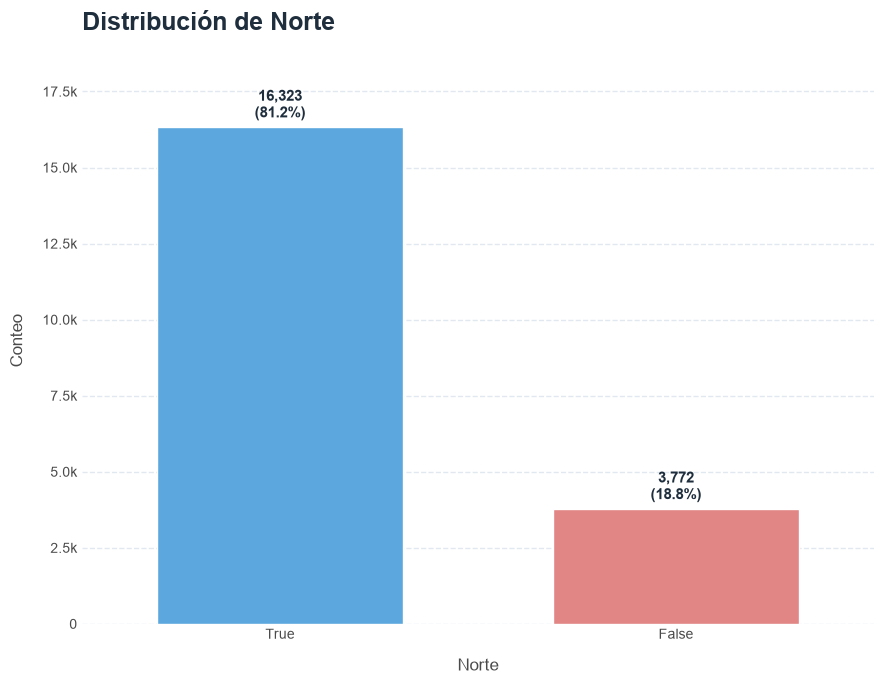

In [263]:
fancy_bars(df_bogota, x="norte", labels="both")

Se hace evidente la desproporción entre los inmuebles norte que se tienen y los que están al sur, eso aunque se consideren más localidades como sur, sin embargo, esto no tiene que ser un problema para esta prueba, pues ambos grupos son lo suficientemente grandes. El único problema que podría ocurrir es una baja representatividad del sur, que será mucho más difícil de diagnosticar sin conocer la población, por lo tanto, se asumirá que ambas muestras son representativas.

In [264]:
numeric_vars = ["log_price_amount", "area_built_m2", "admin_fee"]

In [265]:
resultados = []
for num_var in numeric_vars:
    res = hub_pruebas_num_cat(df_bogota, num_var, ["norte"])
    res = res.copy()
    res.insert(
        0, "variable", num_var
    )  # identifica de qué variable viene cada fila
    resultados.append(res)

df_resultados = pd.concat(resultados, ignore_index=True)
display(df_resultados)

,variable,var_numerica,var_categorica,n_grupos,prueba,estadistico,p_valor,normalidad,homocedasticidad,decision,conclusion,post_hoc
0,log_price_amount,log_price_amount,norte,2,U de Mann-Whitney,14425901.5,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,
1,area_built_m2,area_built_m2,norte,2,U de Mann-Whitney,21670244.5,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,
2,admin_fee,admin_fee,norte,2,U de Mann-Whitney,9105481.5,0.0,no,no,Se rechaza H0,Dependencia: la numérica difiere entre categorías,


Las pruebas respaldan que el factor de estar al norte sí que hace que haya una dependencia con todas las variables, a continuación se plasma de manera gráfica.

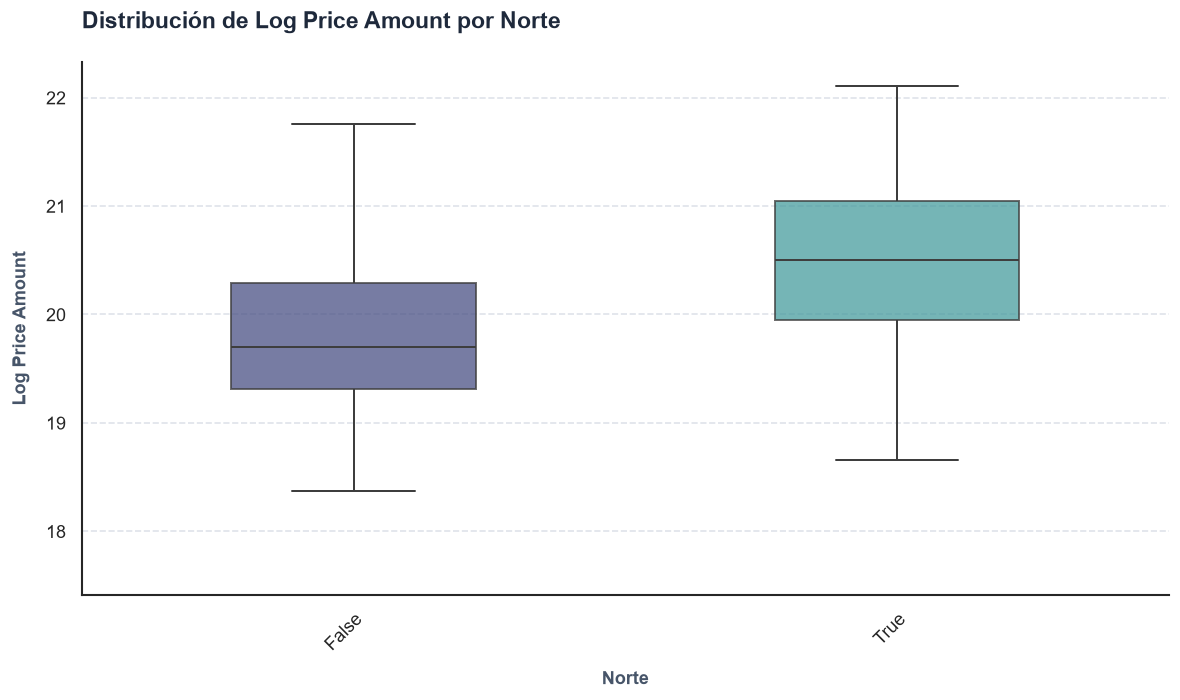

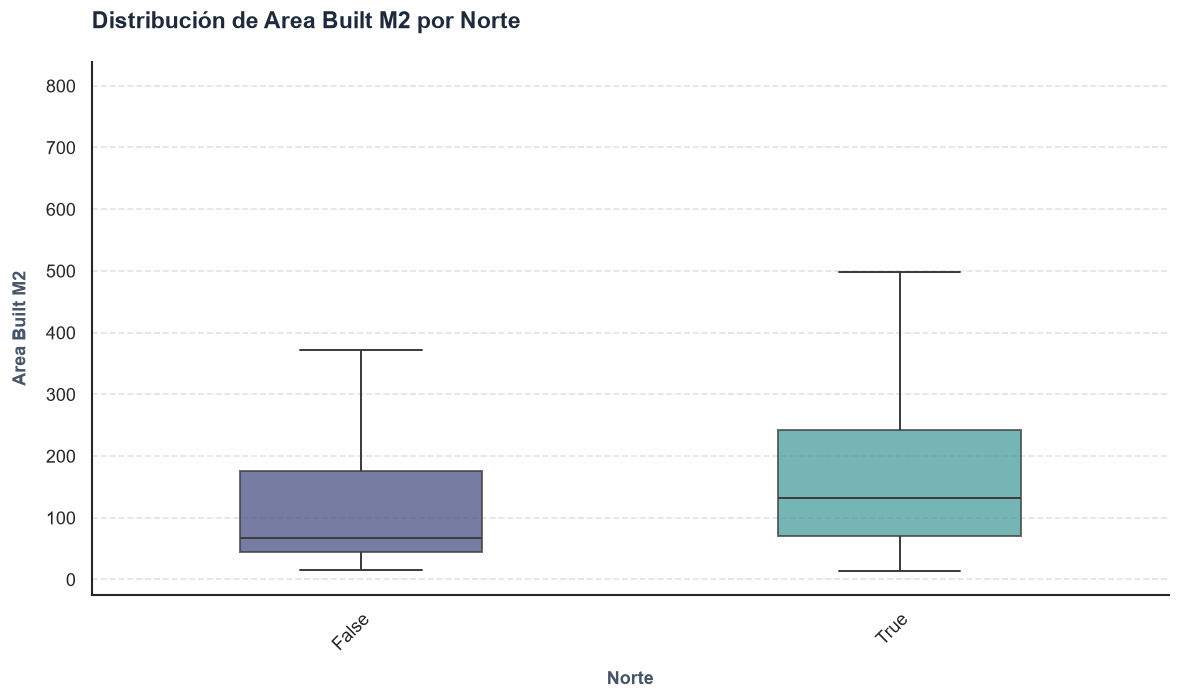

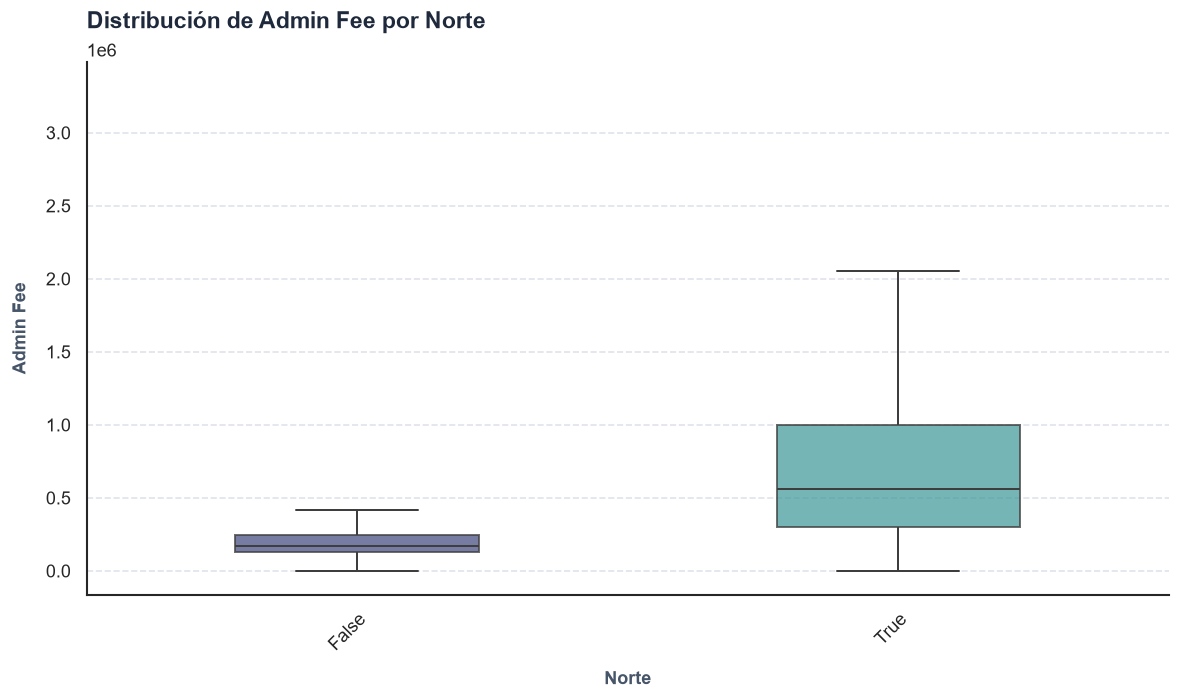

In [266]:
for num_var in numeric_vars:
    plot_segmented_boxplot(df_bogota, num_var, "norte", show_points=False)

La variable que muestra la diferencia más marcada entre norte y sur es el precio, mientras que para las otras 2 la diferencias se ve principalmente que al sur las variables varían menos, tienden a tener un IQR más estrecho y una mediana menor, aunque los bigotes inferiores no son especialmente distintos entre sí. 

In [267]:
def hotteling_comparison_multivariate(df1, df2, cols, alpha=0.05):
    cols = list(cols)
    p = len(cols)  # número de variables (generaliza el caso bivariado)
    n1, n2 = len(df1), len(df2)

    z_1 = df1[cols].mean().to_numpy()
    z_2 = df2[cols].mean().to_numpy()

    cov1 = df1[cols].cov().to_numpy()
    cov2 = df2[cols].cov().to_numpy()

    cov_ig = np.allclose(cov1, cov2, rtol=1e-4, atol=1e-6)

    S_diff = cov1 / n1 + cov2 / n2
    S_pooled = ((n1 - 1) * cov1 + (n2 - 1) * cov2) / (n1 + n2 - 2)

    Z = z_1 - z_2

    # Covarianzas distintas
    S_diff_inv = np.linalg.inv(S_diff)
    T2_diff = Z @ S_diff_inv @ Z
    A1 = (cov1 / n1) @ S_diff_inv
    A2 = (cov2 / n2) @ S_diff_inv
    denominador = (np.trace(A1 @ A1) + np.trace(A1) ** 2) / n1 + (
        np.trace(A2 @ A2) + np.trace(A2) ** 2
    ) / n2
    nu = (p + p**2) / denominador
    F_stat_diff = (nu - p + 1) / (nu * p) * T2_diff
    p_value_diff = f.sf(F_stat_diff, dfn=p, dfd=nu - p + 1)
    reject_null_diff = p_value_diff < alpha

    # Covarianza común (pooled)
    S_pooled_scaled = S_pooled * (1 / n1 + 1 / n2)
    T2_pooled = Z.T @ np.linalg.inv(S_pooled_scaled) @ Z
    F_stat_pooled = ((n1 + n2 - p - 1) / (p * (n1 + n2 - 2))) * T2_pooled
    p_value_pooled = f.sf(F_stat_pooled, dfn=p, dfd=n1 + n2 - p - 1)
    reject_null_pooled = p_value_pooled < alpha

    return {
        "z_1": z_1,
        "z_2": z_2,
        "cov1": cov1,
        "cov2": cov2,
        "matriz de covarianzas comun": cov_ig,
        "S_diff": S_diff,
        "S_pooled": S_pooled,
        "Z": Z,
        "nu": nu,
        "T2_diff": T2_diff,
        "F_stat_diff": F_stat_diff,
        "p_value_diff": p_value_diff,
        "reject_null_diff": reject_null_diff,
        "T2_pooled": T2_pooled,
        "F_stat_pooled": F_stat_pooled,
        "p_value_pooled": p_value_pooled,
        "reject_null_pooled": reject_null_pooled,
    }

In [268]:
res_bonus = hotteling_comparison_multivariate(df_norte, df_sur, numeric_vars)
res_bonus

{'z_1': array([2.04963746e+01, 1.75680661e+02, 7.28359505e+05]),
 'z_2': array([1.98093083e+01, 1.20760653e+02, 2.42311507e+05]),
 'cov1': array([[4.92254392e-01, 7.71810303e+01, 2.48163740e+05],
        [7.71810303e+01, 2.07023796e+04, 2.72326270e+07],
        [2.48163740e+05, 2.72326270e+07, 3.32710008e+11]]),
 'cov2': array([[3.67590268e-01, 5.05743026e+01, 2.46836918e+04],
        [5.05743026e+01, 1.23703153e+04, 9.80043478e+04],
        [2.46836918e+04, 9.80043478e+04, 1.08130774e+11]]),
 'matriz de covarianzas comun': False,
 'S_diff': array([[1.27609454e-04, 1.81361821e-02, 2.17472436e+01],
        [1.81361821e-02, 4.54780597e+00, 1.69434125e+03],
        [2.17472436e+01, 1.69434125e+03, 4.90495908e+07]]),
 'S_pooled': array([[4.68857766e-01, 7.21875515e+01, 2.06221608e+05],
        [7.21875515e+01, 1.91386403e+04, 2.21400743e+07],
        [2.06221608e+05, 2.21400743e+07, 2.90561583e+11]]),
 'Z': array([6.87066236e-01, 5.49200083e+01, 4.86047998e+05]),
 'nu': np.float64(7066.371

In [269]:
numeric_vars

['log_price_amount', 'area_built_m2', 'admin_fee']

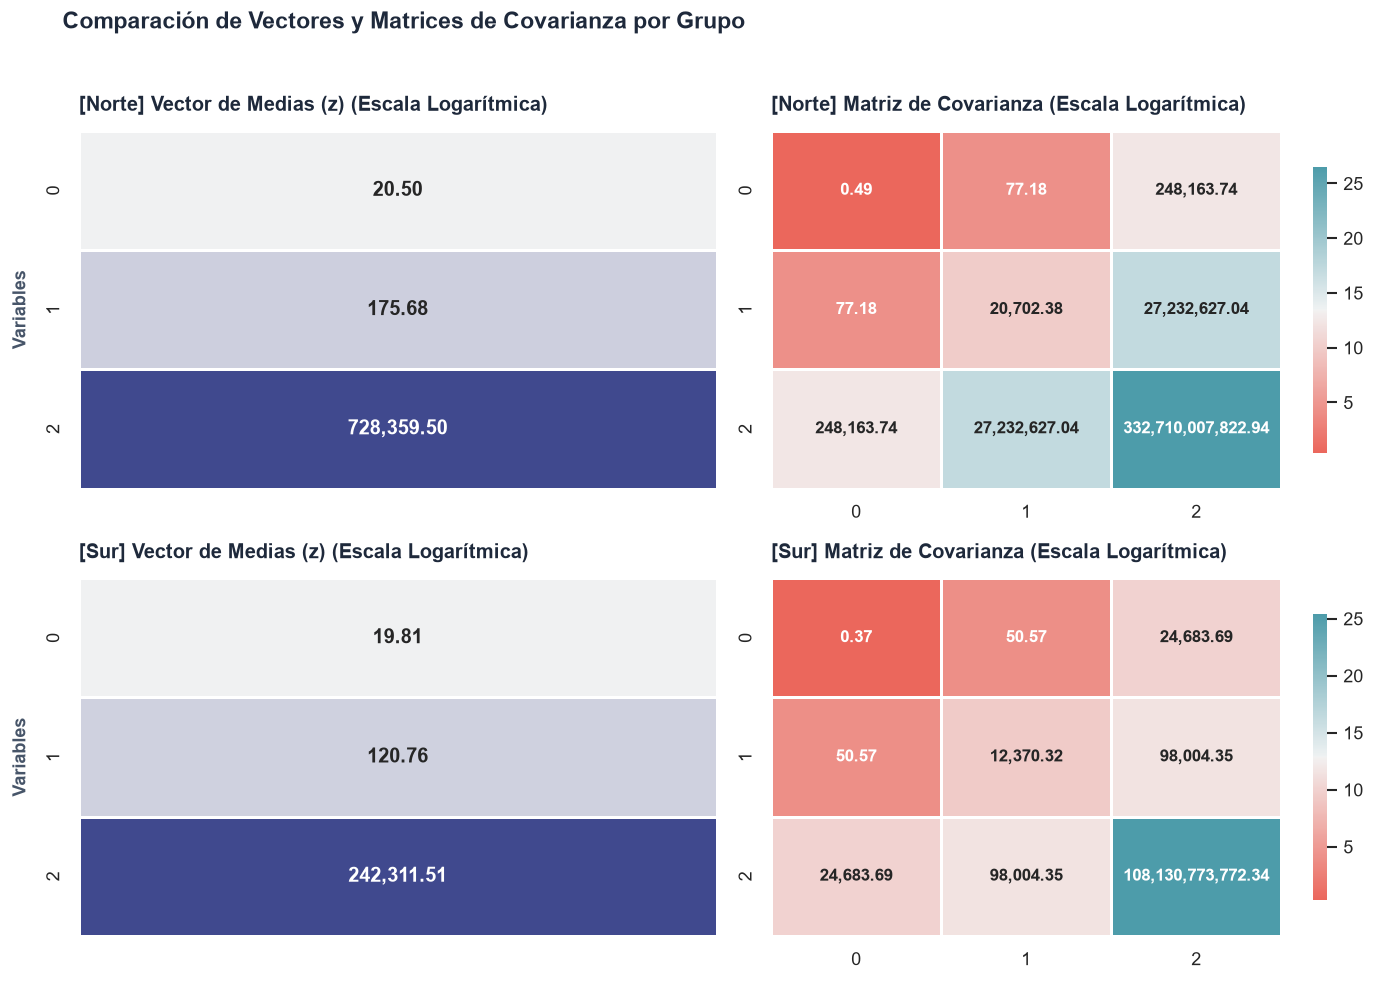

In [270]:
resultados_dict = {
    "Norte": [res_bonus["z_1"], res_bonus["cov1"]],
    "Sur": [res_bonus["z_2"], res_bonus["cov2"]],
}

# Llamada a la función
plot_groups_heatmap(resultados_dict, log_scale=True)

In [271]:
# diferencia entre precios en escala original

precios_log_norte = res_bonus["z_1"][0]
precios_log_sur = res_bonus["z_2"][0]

print(
    f"Precios en escala log\n  Norte {precios_log_norte}\n"
    f"  Sur {precios_log_sur}"
)
print(
    f"Precios en escala original\n  Norte {np.exp(precios_log_norte):,.2f}\n"
    f"  Sur {np.exp(precios_log_sur):,.2f}"
)

Precios en escala log
  Norte 20.49637456116616
  Sur 19.80930832546577
Precios en escala original
  Norte 797,007,431.59
  Sur 400,934,377.79


Solo viendo el vector de medias se puede apreciar cómo todas las variables consideradas tienen una diferencia amplia entre norte y sur, siendo las más drásticas el precio y la administración, no obstante, el área construida también presenta una diferencia considerable, esto es el primer indicio (junto a las pruebas y evidencias gráficas mostradas anteriormente) de que se rechazará la hipótesis nula.

Dado que las matrices de cov son realmente distintas entre sí, se opta por utilizar las conclusiones obtenidas mediante $S_{diff}$, dicho esto, el valor p utilizando ese método es de **0.0**, lo cual constituye un claro rechazo a la hipótesis nula a un 95% de confianza, por lo tanto, hay evidencia suficiente para afirmar que los vectores de medias difieren entre sí (esto considerando la asociación entre variables gracias a la distancia de Mahalanobis, detalle que se obvió en oportunidades anteriores).

En el contexto, eso indica que los inmuebles que están en el norte y los que están en el sur son estadísticamente diferentes entre sí en muchas de las características físicas clave de estos, lo cual a su vez posiblemente indique que los cliente que se interesan en cada sector de la ciudad sean diferentes.